# Лабораторна робота №4

## Дослідження дерев рішень та ансамблевих методів у задачі багатокласової класифікації за наявності пропущених значень

**Виконав:** студент групи ФеІ-44 Махнюк Юрій

**Індивідуальний варіант:** №8

## Мета роботи

Дослідити та порівняти три алгоритми класифікації:
Decision Tree, Random Forest та XGBoost на датасеті
Annealing, що містить пропущені значення.

Дослідити вплив способів обробки пропусків на якість
класифікації, виконати оптимізацію гіперпараметрів
за допомогою Optuna, вкладену крос-валідацію,
статистичне порівняння моделей та інтерпретацію
їхніх прогнозів за допомогою MDI, Permutation
Importance і SHAP.

## 1. Підготовка та первинний аналіз даних (EDA)

### 1.1. Імпорт бібліотек та налаштування середовища

Імпортуємо необхідні бібліотеки для обробки даних,
візуалізації, навчання моделей, оптимізації
гіперпараметрів та статистичного аналізу.

Для забезпечення відтворюваності результатів
встановлюємо SEED = 42 + N = 50, де N = 8 —
номер студента у списку групи.

In [2]:
import sys
import random
import time
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import scipy.stats as stats
import optuna
import shap
import joblib

from sklearn.datasets import fetch_openml

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    cross_validate,
    cross_val_score,
    cross_val_predict
)

from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.inspection import permutation_importance

from IPython.display import display

SEED = 42 + 8

random.seed(SEED)
np.random.seed(SEED)

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

Path("artifacts").mkdir(exist_ok=True)

print("SEED:", SEED)
print("Python:", sys.version.split()[0])

SEED: 50
Python: 3.11.9


### 1.2. Перевірка версій бібліотек

Для забезпечення відтворюваності експериментів
зафіксуємо версії основних бібліотек, використаних
під час виконання лабораторної роботи.

In [3]:
libraries = [
    "numpy",
    "pandas",
    "scikit-learn",
    "xgboost",
    "optuna",
    "shap",
    "scipy",
    "matplotlib",
    "seaborn",
    "joblib"
]

versions = pd.DataFrame({
    "Library": libraries,
    "Version": [version(lib) for lib in libraries]
})

display(versions)

,Library,Version
0,numpy,2.4.6
1,pandas,3.1.1
2,scikit-learn,1.9.1
3,xgboost,3.2.0
4,optuna,5.1.0
5,shap,0.51.0
6,scipy,1.17.1
7,matplotlib,3.11.2
8,seaborn,0.13.2
9,joblib,1.6.0


### 1.3. Завантаження датасету Annealing

Для дослідження використаємо датасет Annealing
(version=1) із платформи OpenML, який описує
параметри промислового процесу відпалу сталі.

Датасет містить числові, бінарні та категоріальні
ознаки, значну кількість пропущених значень,
а також незбалансовану багатокласову цільову змінну.

Визначимо матрицю ознак X та цільову змінну y.
Категоріальні ознаки приведемо до типу object.

In [4]:
data = fetch_openml(
    name="anneal",
    version=1,
    as_frame=True,
    parser="liac-arff"
)

X = data.data.copy()
y = data.target.copy()

# Перетворення категоріальних ознак
cat_cols = X.select_dtypes(
    exclude="number"
).columns

X[cat_cols] = X[cat_cols].astype(object)

# Уніфікація позначень пропущених значень
X = X.replace("?", np.nan)

print("Назва датасету:", data.details["name"])
print("Версія:", data.details["version"])
print("Кількість спостережень:", X.shape[0])
print("Кількість ознак:", X.shape[1])
print("Кількість класів:", y.nunique())

display(X.head())

Назва датасету: anneal
Версія: 1
Кількість спостережень: 898
Кількість ознак: 38
Кількість класів: 5


,family,product-type,steel,carbon,hardness,temper_rolling,condition,formability,strength,non-ageing,surface-finish,surface-quality,enamelability,bc,bf,bt,bw%2Fme,bl,m,chrom,phos,cbond,marvi,exptl,ferro,corr,blue%2Fbright%2Fvarn%2Fclean,lustre,jurofm,s,p,shape,thick,width,len,oil,bore,packing
0,NaN,C,A,8.0,0.0,NaN,S,NaN,0.0,NaN,NaN,G,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,COIL,0.700,610.0,0.0,NaN,0,NaN
1,NaN,C,R,0.0,0.0,NaN,S,2,0.0,NaN,NaN,E,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Y,NaN,NaN,NaN,COIL,3.200,610.0,0.0,NaN,0,NaN
2,NaN,C,R,0.0,0.0,NaN,S,2,0.0,NaN,NaN,E,NaN,NaN,Y,NaN,B,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SHEET,0.700,1300.0,762.0,NaN,0,NaN
3,NaN,C,A,0.0,60.0,T,NaN,NaN,0.0,NaN,NaN,G,NaN,NaN,NaN,NaN,M,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,COIL,2.801,385.1,0.0,NaN,0,NaN
4,NaN,C,A,0.0,60.0,T,NaN,NaN,0.0,NaN,NaN,G,NaN,NaN,NaN,NaN,B,Y,NaN,NaN,NaN,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SHEET,0.801,255.0,269.0,NaN,0,NaN


### 1.4. Аналіз структури датасету

Проаналізуємо розмірність набору даних, типи ознак,
кількість числових та категоріальних змінних,
а також загальну кількість пропущених значень.

In [5]:
X.info()

numeric_cols = X.select_dtypes(
    include="number"
).columns

categorical_cols = X.select_dtypes(
    exclude="number"
).columns

summary = pd.DataFrame({
    "Характеристика": [
        "Кількість спостережень",
        "Кількість ознак",
        "Числові ознаки",
        "Категоріальні ознаки",
        "Кількість класів",
        "Пропущені значення",
        "Ознаки з пропусками",
        "Повністю порожні ознаки",
        "Дублікати рядків"
    ],
    "Значення": [
        X.shape[0],
        X.shape[1],
        len(numeric_cols),
        len(categorical_cols),
        y.nunique(),
        X.isna().sum().sum(),
        X.isna().any().sum(),
        X.isna().all().sum(),
        X.duplicated().sum()
    ]
})

display(summary)

<class 'pandas.DataFrame'>
RangeIndex: 898 entries, 0 to 897
Data columns (total 38 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   family                        126 non-null    object 
 1   product-type                  898 non-null    object 
 2   steel                         812 non-null    object 
 3   carbon                        898 non-null    float64
 4   hardness                      898 non-null    float64
 5   temper_rolling                137 non-null    object 
 6   condition                     595 non-null    object 
 7   formability                   580 non-null    object 
 8   strength                      898 non-null    float64
 9   non-ageing                    105 non-null    object 
 10  surface-finish                9 non-null      object 
 11  surface-quality               654 non-null    object 
 12  enamelability                 16 non-null     object 
 13  bc              

,Характеристика,Значення
0,Кількість спостережень,898
1,Кількість ознак,38
2,Числові ознаки,6
3,Категоріальні ознаки,32
4,Кількість класів,5
5,Пропущені значення,22175
6,Ознаки з пропусками,29
7,Повністю порожні ознаки,6
8,Дублікати рядків,12


**Висновок.** Датасет Annealing версії 1 із платформи
OpenML містить 898 спостережень та 38 ознак, серед яких
6 числових і 32 категоріальні. Цільова змінна представлена
п'ятьма класами.

Виявлено 22175 пропущених значень, що становить приблизно
64,98% від загальної кількості значень. Пропуски присутні
у 29 ознаках, причому 6 ознак є повністю порожніми.
Також виявлено 12 повторюваних рядків матриці ознак.

Отримані результати підтверджують необхідність дослідження
методів обробки пропущених значень перед навчанням моделей.

### 1.5. Аналіз та візуалізація пропущених значень

Для кожної ознаки визначимо кількість та відсоток
пропущених значень. Побудуємо горизонтальну стовпчикову
діаграму, яка дозволить визначити ознаки з найбільшою
часткою пропусків.

In [6]:
missing_stats = pd.DataFrame({
    "Missing count": X.isna().sum(),
    "Missing percentage": X.isna().mean() * 100,
    "Unique non-null": X.nunique()
}).sort_values("Missing percentage", ascending=False)

display(missing_stats.round(2))

print(
    "Загальна частка пропусків:",
    f"{X.isna().mean().mean() * 100:.2f}%"
)

,Missing count,Missing percentage,Unique non-null
marvi,898,100.00,0
s,898,100.00,0
p,898,100.00,0
corr,898,100.00,0
jurofm,898,100.00,0
m,898,100.00,0
bc,897,99.89,1
exptl,896,99.78,1
blue%2Fbright%2Fvarn%2Fclean,892,99.33,3
phos,891,99.22,1


Загальна частка пропусків: 64.98%


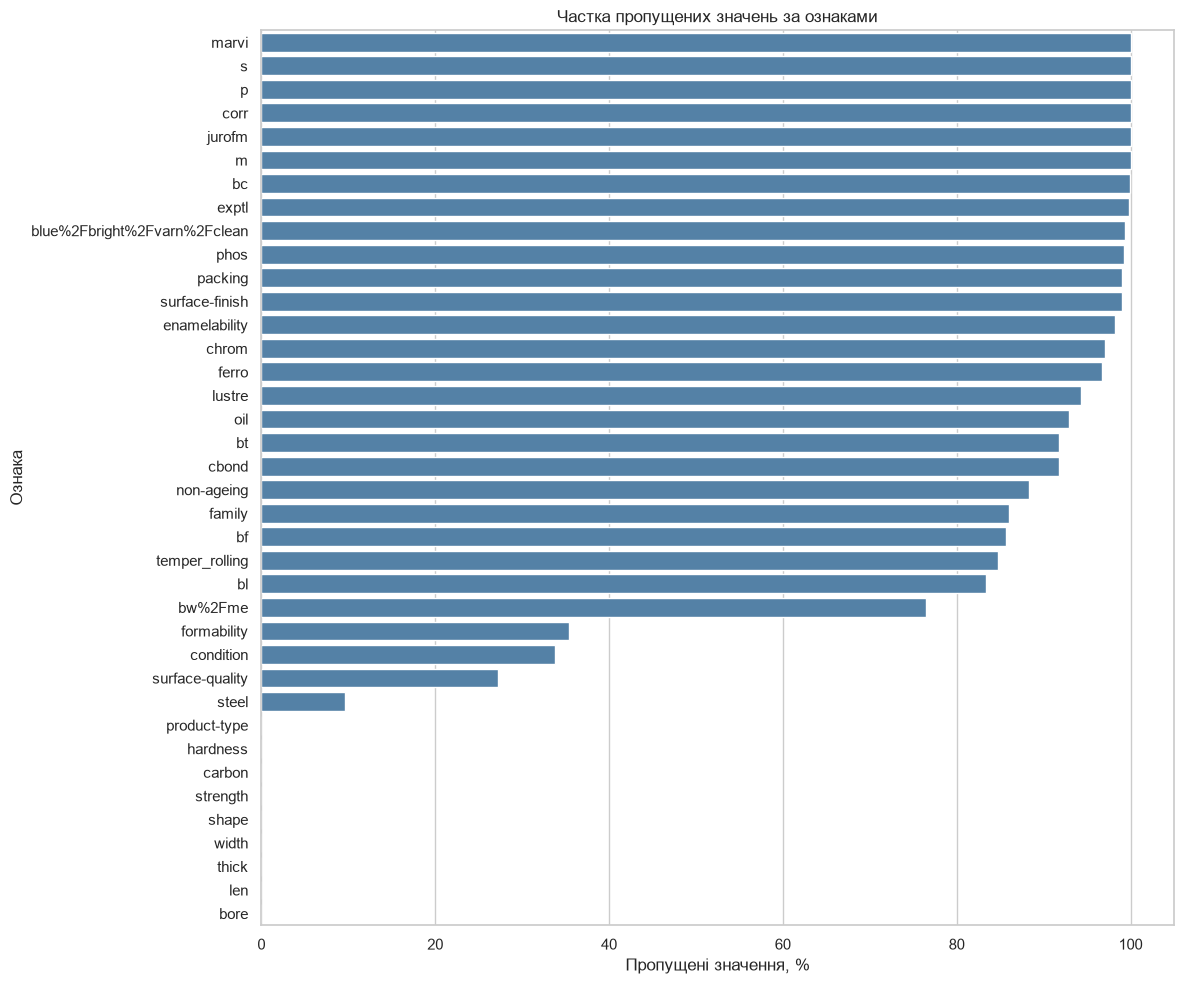

In [7]:
plt.figure(figsize=(12, 10))

sns.barplot(
    data=missing_stats.reset_index(),
    x="Missing percentage",
    y="index",
    color="steelblue"
)

plt.title("Частка пропущених значень за ознаками")
plt.xlabel("Пропущені значення, %")
plt.ylabel("Ознака")
plt.xlim(0, 105)
plt.tight_layout()
plt.show()

**Висновок.** Загальна частка пропущених значень становить
64,98%. Шість ознак є повністю порожніми, а 19 ознак
мають понад 75% пропущених значень, не враховуючи
повністю порожні ознаки.

Лише 9 із 38 ознак не містять пропусків. Така структура
даних обґрунтовує необхідність порівняння різних
способів обробки пропущених значень.

### 1.6. Виявлення порожніх і константних ознак

Повністю порожні ознаки не містять інформації про об'єкти,
а константні ознаки без пропусків не дозволяють розрізняти
спостереження.

Окремо визначимо ознаки, які мають лише одне унікальне
непропущене значення, але містять пропуски. Такі ознаки
можуть бути корисними завдяки індикаторам пропусків.

На цьому етапі визначимо кандидатів на видалення.
Остаточне видалення виконуватимемо всередині пайплайна,
щоб уникнути витоку даних під час крос-валідації.

In [8]:
empty_cols = X.columns[X.isna().all()].tolist()

constant_cols = X.columns[
    (X.nunique() == 1) & (~X.isna().any())
].tolist()

constant_with_missing = X.columns[
    (X.nunique() == 1) & (X.isna().any())
].tolist()

print("Повністю порожні ознаки:")
print(empty_cols)

print("\nКонстантні ознаки без пропусків:")
print(constant_cols)

print("\nКонстантні ознаки з пропусками:")
print(constant_with_missing)

drop_cols = empty_cols + constant_cols

print("\nКількість кандидатів на видалення:", len(drop_cols))
print("Початкова кількість ознак:", X.shape[1])
print("Очікувана кількість ознак:", X.shape[1] - len(drop_cols))

Повністю порожні ознаки:
['m', 'marvi', 'corr', 'jurofm', 's', 'p']

Константні ознаки без пропусків:
['product-type']

Константні ознаки з пропусками:
['temper_rolling', 'non-ageing', 'surface-finish', 'bc', 'bf', 'bt', 'bl', 'chrom', 'phos', 'cbond', 'exptl', 'ferro', 'lustre']

Кількість кандидатів на видалення: 7
Початкова кількість ознак: 38
Очікувана кількість ознак: 31


**Висновок.** Виявлено 6 повністю порожніх ознак
(m, marvi, corr, jurofm, s, p) та одну константну
ознаку без пропусків (product-type).

Також виявлено 13 ознак, які мають лише одне унікальне
непропущене значення. Їх доцільно залишити, оскільки
сам факт відсутності значення може містити інформацію
для класифікації.

Після видалення 7 неінформативних ознак очікувана
кількість початкових ознак становитиме 31.
Видалення виконуватиметься всередині пайплайна.

### 1.7. Аналіз розподілу цільової змінної

Дослідимо кількість спостережень кожного класу та їхню
відносну частку в датасеті.

Особливу увагу приділимо дисбалансу класів і кількості
спостережень найменшого класу, оскільки це впливає
на можливість проведення стратифікованої та вкладеної
крос-валідації.

In [9]:
class_stats = pd.DataFrame({
    "Count": y.value_counts().sort_index(),
    "Percentage": (
        y.value_counts(normalize=True).sort_index() * 100
    )
})

display(class_stats.round(2))

print("Найбільший клас:", class_stats["Count"].idxmax())
print("Найменший клас:", class_stats["Count"].idxmin())

print("Розмір найбільшого класу:", class_stats["Count"].max())
print("Розмір найменшого класу:", class_stats["Count"].min())

imbalance_ratio = (
    class_stats["Count"].max() /
    class_stats["Count"].min()
)

print(f"Коефіцієнт дисбалансу: {imbalance_ratio:.2f}")

,Count,Percentage
class,,
1,8,0.89
2,99,11.02
3,684,76.17
5,67,7.46
U,40,4.45


Найбільший клас: 3
Найменший клас: 1
Розмір найбільшого класу: 684
Розмір найменшого класу: 8
Коефіцієнт дисбалансу: 85.50


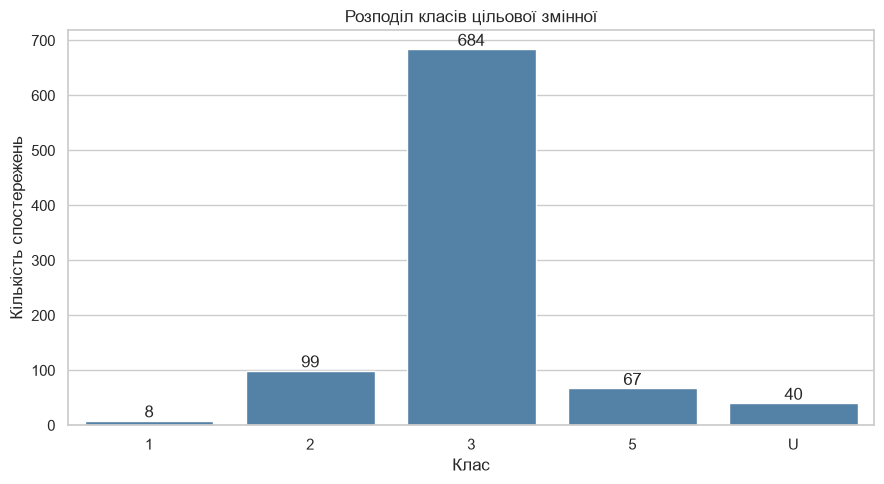

In [10]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=class_stats.index.astype(str),
    y=class_stats["Count"],
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Розподіл класів цільової змінної")
plt.xlabel("Клас")
plt.ylabel("Кількість спостережень")
plt.tight_layout()
plt.show()

**Висновок.** Датасет характеризується значним дисбалансом
класів. Домінуючим є клас 3, який містить 684 спостереження
(76,17%), тоді як найменший клас 1 містить лише
8 спостережень (0,89%).

Коефіцієнт дисбалансу становить 85,50.

Прийнято рішення залишити всі п'ять класів, оскільки
видалення або об'єднання рідкісних класів змінює
початкову постановку задачі класифікації.

Після стратифікованого поділу очікується приблизно
6 спостережень класу 1 у тренувальній вибірці та
2 у тестовій. Цього достатньо для зовнішньої
5-блочної та внутрішньої 3-блочної крос-валідації,
що буде додатково перевірено після поділу даних.

Через значний дисбаланс основною метрикою оцінювання
обрано macro F1, а додатковими — accuracy та
balanced accuracy.

### 1.8. Дослідження механізму виникнення пропущених значень

Розрізняють три основні механізми виникнення пропусків:

- MCAR (Missing Completely At Random) — пропуски
  виникають повністю випадково.
- MAR (Missing At Random) — виникнення пропусків
  залежить від інших спостережуваних змінних.
- MNAR (Missing Not At Random) — виникнення пропусків
  залежить від самого відсутнього значення або
  неспостережуваних чинників.

Для п'яти ознак із найбільшою часткою пропусків,
виключаючи повністю порожні ознаки, побудуємо таблиці
спряженості між наявністю пропуску та цільовим класом.

Сформулюємо статистичні гіпотези:

- H0: наявність пропуску не залежить від класу.
- H1: наявність пропуску залежить від класу.

Рівень статистичної значущості alpha = 0.05.

Для таблиць із достатніми очікуваними частотами
використаємо критерій хі-квадрат Пірсона, а для
малих частот — узагальнений точний критерій Фішера
з оцінюванням p-значення методом Монте-Карло.

In [11]:
ALPHA = 0.05

top_missing_features = missing_stats[
    (missing_stats["Missing percentage"] > 0) &
    (missing_stats["Missing percentage"] < 100)
].head(5).index.tolist()

print("Ознаки для дослідження:")
print(top_missing_features)

missing_test_results = []

for feature in top_missing_features:

    contingency = pd.crosstab(
        X[feature].isna().map({
            True: "Missing",
            False: "Not missing"
        }),
        y
    )

    print(f"\nОзнака: {feature}")
    display(contingency)

    chi2, p_chi2, dof, expected = stats.chi2_contingency(
        contingency
    )

    if (expected < 5).any():
        result = stats.fisher_exact(
            contingency.to_numpy(),
            method=stats.MonteCarloMethod(
                n_resamples=100_000,
                rng=np.random.default_rng(SEED)
            )
        )

        p_value = result.pvalue
        method = "Fisher (Monte Carlo)"

    else:
        p_value = p_chi2
        method = "Chi-square"

    missing_test_results.append({
        "Feature": feature,
        "Missing (%)": X[feature].isna().mean() * 100,
        "Method": method,
        "Chi-square": chi2,
        "Min expected": expected.min(),
        "p-value": p_value,
        "Significant": p_value < ALPHA,
        "Conclusion": (
            "Відхиляємо H0"
            if p_value < ALPHA
            else "Не відхиляємо H0"
        )
    })

missing_test_df = pd.DataFrame(missing_test_results)

display(missing_test_df.round(6))

Ознаки для дослідження:
['bc', 'exptl', 'blue%2Fbright%2Fvarn%2Fclean', 'phos', 'packing']

Ознака: bc


class,1,2,3,5,U
bc,,,,,
Missing,8,99,683,67,40
Not missing,0,0,1,0,0



Ознака: exptl


class,1,2,3,5,U
exptl,,,,,
Missing,6,99,684,67,40
Not missing,2,0,0,0,0



Ознака: blue%2Fbright%2Fvarn%2Fclean


class,1,2,3,5,U
blue%2Fbright%2Fvarn%2Fclean,,,,,
Missing,7,95,683,67,40
Not missing,1,4,1,0,0



Ознака: phos


class,1,2,3,5,U
phos,,,,,
Missing,8,99,684,60,40
Not missing,0,0,0,7,0



Ознака: packing


class,1,2,3,5,U
packing,,,,,
Missing,8,99,675,67,40
Not missing,0,0,9,0,0


,Feature,Missing (%),Method,Chi-square,Min expected,p-value,Significant,Conclusion
0,bc,99.888641,Fisher (Monte Carlo),0.313214,0.008909,1.000000,False,Не відхиляємо H0
1,exptl,99.777283,Fisher (Monte Carlo),222.996652,0.017817,0.000100,True,Відхиляємо H0
2,blue%2Fbright%2Fvarn%2Fclean,99.331849,Fisher (Monte Carlo),37.365354,0.053452,0.000470,True,Відхиляємо H0
3,phos,99.220490,Fisher (Monte Carlo),87.502990,0.062361,0.000010,True,Відхиляємо H0
4,packing,98.997773,Fisher (Monte Carlo),2.844296,0.080178,0.798262,False,Не відхиляємо H0


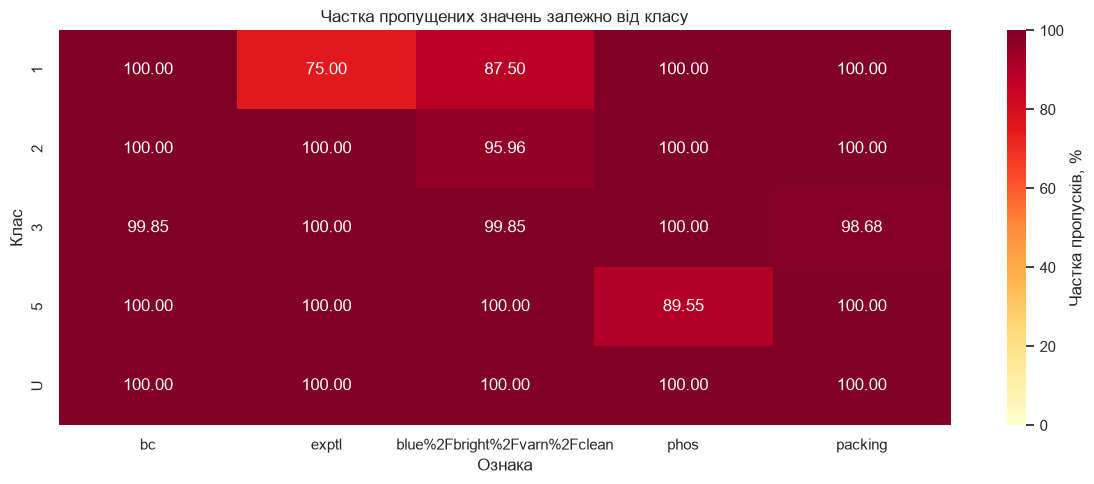

In [12]:
missing_by_class = (
    X[top_missing_features]
    .isna()
    .groupby(y, observed=True)
    .mean() * 100
)

plt.figure(figsize=(12, 5))

sns.heatmap(
    missing_by_class,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Частка пропусків, %"}
)

plt.title("Частка пропущених значень залежно від класу")
plt.xlabel("Ознака")
plt.ylabel("Клас")
plt.tight_layout()
plt.show()

**Висновок.** За результатами статистичного аналізу
для ознак exptl (p = 0.000100),
blue%2Fbright%2Fvarn%2Fclean (p = 0.000470)
та phos (p = 0.000010) відхилено нульову гіпотезу
про незалежність пропусків від цільового класу.

Для ознак bc (p = 1.000000) та packing (p = 0.798262)
статистично значущого зв'язку не виявлено.

Особливо показовою є ознака exptl, непропущені
значення якої зустрічаються лише у класі 1,
та ознака phos — лише у класі 5.

Отримані результати свідчать, що механізм MCAR
не є характерним для всіх досліджуваних ознак.
Можливими поясненнями є механізми MAR, MNAR,
а також структурна природа пропусків.

Однозначно розрізнити MAR та MNAR на основі
проведеного аналізу неможливо.

Таким чином, використання бінарних індикаторів
пропусків потенційно може покращити якість
класифікації, особливо для рідкісних класів.

### 1.9. Кодування цільової змінної

Для забезпечення сумісності з алгоритмом XGBoost
перетворимо початкові мітки класів на послідовні
цілочисельні значення від 0 до K-1 за допомогою
LabelEncoder.

Кодування не змінює кількість класів та їхній розподіл.

In [13]:
label_encoder = LabelEncoder()

y_enc = label_encoder.fit_transform(y)

class_mapping = pd.DataFrame({
    "Original class": label_encoder.classes_,
    "Encoded class": np.arange(len(label_encoder.classes_))
})

display(class_mapping)

print("Кількість класів:", len(label_encoder.classes_))
print("Унікальні закодовані класи:", np.unique(y_enc))

,Original class,Encoded class
0,1,0
1,2,1
2,3,2
3,5,3
4,U,4


Кількість класів: 5
Унікальні закодовані класи: [0 1 2 3 4]


**Висновок.** Цільову змінну успішно закодовано
за допомогою LabelEncoder. Початкові класи
1, 2, 3, 5 та U перетворено відповідно
на 0, 1, 2, 3 та 4.

Усі п'ять класів збережено, що забезпечує
сумісність даних з алгоритмом XGBoost.

## 2. Поділ даних та побудова пайплайнів попередньої обробки

### 2.1. Стратифікований поділ даних

Розділимо датасет на тренувальну (80%) та тестову
(20%) вибірки за допомогою стратифікованого поділу.

Стратифікація дозволяє зберегти приблизно однакові
пропорції класів в обох вибірках, що особливо
важливо в умовах значного дисбалансу.

Тренувальна вибірка використовуватиметься для навчання,
крос-валідації та оптимізації гіперпараметрів.
Тестова вибірка не використовуватиметься для навчання
або підбору гіперпараметрів.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_enc,
    test_size=0.2,
    stratify=y_enc,
    random_state=SEED
)

print("Розмір тренувальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

split_stats = pd.DataFrame({
    "Class": label_encoder.classes_,
    "Total": np.bincount(y_enc),
    "Train": np.bincount(y_train),
    "Test": np.bincount(y_test),
    "Train (%)": np.bincount(y_train) / len(y_train) * 100,
    "Test (%)": np.bincount(y_test) / len(y_test) * 100
})

display(split_stats.round(2))

Розмір тренувальної вибірки: (718, 38)
Розмір тестової вибірки: (180, 38)


,Class,Total,Train,Test,Train (%),Test (%)
0,1,8,6,2,0.84,1.11
1,2,99,79,20,11.00,11.11
2,3,684,547,137,76.18,76.11
3,5,67,54,13,7.52,7.22
4,U,40,32,8,4.46,4.44


### 2.2. Перевірка можливості проведення вкладеної крос-валідації

Через малу кількість спостережень класу 1 необхідно
перевірити, чи достатньо об'єктів кожного класу
для проведення зовнішньої 5-блочної та внутрішньої
3-блочної стратифікованої крос-валідації.

Це дозволить уникнути ситуацій, коли окремий клас
відсутній у тренувальному або валідаційному блоці.

In [15]:
N_CLASSES = len(label_encoder.classes_)

outer = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

inner = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=SEED
)

cv_check = []

for fold, (tr_idx, va_idx) in enumerate(
    outer.split(X_train, y_train), start=1
):
    y_outer_train = y_train[tr_idx]
    y_outer_val = y_train[va_idx]

    min_inner_train = []
    min_inner_val = []

    for inner_tr, inner_va in inner.split(
        X_train.iloc[tr_idx],
        y_outer_train
    ):
        min_inner_train.append(
            np.bincount(
                y_outer_train[inner_tr],
                minlength=N_CLASSES
            ).min()
        )

        min_inner_val.append(
            np.bincount(
                y_outer_train[inner_va],
                minlength=N_CLASSES
            ).min()
        )

    cv_check.append({
        "Outer fold": fold,
        "Min outer train": np.bincount(
            y_outer_train, minlength=N_CLASSES
        ).min(),
        "Min outer validation": np.bincount(
            y_outer_val, minlength=N_CLASSES
        ).min(),
        "Min inner train": min(min_inner_train),
        "Min inner validation": min(min_inner_val)
    })

cv_check_df = pd.DataFrame(cv_check)

display(cv_check_df)

assert cv_check_df.iloc[:, 1:].min().min() > 0

print("Усі класи представлені в кожному блоці.")

,Outer fold,Min outer train,Min outer validation,Min inner train,Min inner validation
0,1,5,1,3,1
1,2,5,1,3,1
2,3,4,2,2,1
3,4,5,1,3,1
4,5,5,1,3,1


Усі класи представлені в кожному блоці.


**Висновок.** У результаті стратифікованого поділу
отримано 718 тренувальних та 180 тестових спостережень.
Пропорції класів в обох вибірках практично однакові.

Найменший клас 1 представлений шістьма спостереженнями
у тренувальній вибірці та двома у тестовій.

Перевірка зовнішньої 5-блочної та внутрішньої
3-блочної крос-валідації підтвердила наявність усіх
п'яти класів у кожному тренувальному та валідаційному
блоці.

Таким чином, можна проводити вкладену крос-валідацію
без видалення або об'єднання рідкісних класів.
Водночас мала кількість спостережень класу 1 може
спричинити значну варіативність оцінок macro F1.

### 2.3. Реалізація видалення неінформативних ознак

Створимо власний трансформер для автоматичного
видалення повністю порожніх і константних ознак.

Ознаки з одним унікальним непропущеним значенням
та наявними пропусками залишатимемо, оскільки
індикатори їхніх пропусків можуть бути інформативними.

Трансформер буде частиною Pipeline, завдяки чому
відбір ознак здійснюватиметься виключно на
тренувальних даних відповідного блоку.

In [16]:
from sklearn.base import BaseEstimator, TransformerMixin


class DropUninformativeFeatures(
    BaseEstimator, TransformerMixin
):

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(
            X.columns, dtype=object
        )

        empty = X.isna().all()

        constant = (
            (X.nunique(dropna=True) == 1) &
            (~X.isna().any())
        )

        self.drop_columns_ = X.columns[
            empty | constant
        ].tolist()

        self.keep_columns_ = X.columns[
            ~(empty | constant)
        ].tolist()

        return self

    def transform(self, X):
        return X[self.keep_columns_].copy()

    def get_feature_names_out(self, input_features=None):
        return np.asarray(
            self.keep_columns_, dtype=object
        )

### 2.4. Створення двох варіантів попередньої обробки

Варіант A (базова імпутація):
- заповнення числових пропусків медіаною;
- заповнення категоріальних пропусків модою;
- One-Hot Encoding категоріальних ознак.

Варіант B (імпутація з індикаторами пропусків):
- усі операції варіанту A;
- додавання бінарних індикаторів пропущених значень.

Індикатор набуває значення 1, якщо початкове
значення було пропущене, та 0 — якщо воно було наявне.

Індикатори формуються на основі даних до імпутації.
Усі перетворення реалізовано за допомогою
ColumnTransformer та Pipeline для запобігання
витоку даних.

In [17]:
def build_preprocessor(with_indicators: bool):

    transformers = [
        (
            "num",
            SimpleImputer(strategy="median"),
            make_column_selector(dtype_include="number")
        ),
        (
            "cat",
            Pipeline([
                (
                    "impute",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "onehot",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=False
                    )
                )
            ]),
            make_column_selector(dtype_exclude="number")
        )
    ]

    if with_indicators:
        transformers.append((
            "miss",
            MissingIndicator(
                features="missing-only",
                error_on_new=False
            ),
            make_column_selector()
        ))

    return ColumnTransformer(transformers)

### 2.5. Перевірка роботи попередньої обробки

Перевіримо коректність роботи обох варіантів
попередньої обробки на тренувальній вибірці.

Визначимо кількість ознак після перетворення,
кількість доданих індикаторів та наявність
пропущених значень після імпутації.

Ця перевірка є демонстраційною. Під час подальшої
крос-валідації трансформери навчатимуться заново
всередині кожного тренувального блоку.

In [18]:
preprocessing_results = []

for variant, with_indicators in [
    ("A", False),
    ("B", True)
]:

    prep = Pipeline([
        ("drop", DropUninformativeFeatures()),
        ("prep", build_preprocessor(with_indicators))
    ])

    X_processed = prep.fit_transform(X_train)

    feature_names = prep.get_feature_names_out()

    indicators_count = sum(
        name.startswith("miss__")
        for name in feature_names
    )

    preprocessing_results.append({
        "Variant": variant,
        "Original features": X_train.shape[1],
        "Removed features": len(
            prep.named_steps["drop"].drop_columns_
        ),
        "Processed features": X_processed.shape[1],
        "Missing indicators": indicators_count,
        "Remaining NaN": np.isnan(X_processed).sum()
    })

    print(f"\nВаріант {variant}")
    print("Видалені ознаки:")
    print(prep.named_steps["drop"].drop_columns_)

    assert not np.isnan(X_processed).any()

    if with_indicators:
        print("\nІндикатори пропусків:")

        display(pd.DataFrame({
            "Indicator": [
                name for name in feature_names
                if name.startswith("miss__")
            ]
        }))

preprocessing_df = pd.DataFrame(preprocessing_results)

display(preprocessing_df)


Варіант A
Видалені ознаки:
['product-type', 'm', 'marvi', 'corr', 'jurofm', 's', 'p']

Варіант B
Видалені ознаки:
['product-type', 'm', 'marvi', 'corr', 'jurofm', 's', 'p']

Індикатори пропусків:


,Indicator
0,miss__missingindicator_family
1,miss__missingindicator_steel
2,miss__missingindicator_temper_rolling
3,miss__missingindicator_condition
4,miss__missingindicator_formability
5,miss__missingindicator_non-ageing
6,miss__missingindicator_surface-finish
7,miss__missingindicator_surface-quality
8,miss__missingindicator_enamelability
9,miss__missingindicator_bc


,Variant,Original features,Removed features,Processed features,Missing indicators,Remaining NaN
0,A,38,7,54,0,0
1,B,38,7,77,23,0


**Висновок.** В обох варіантах попередньої обробки
видалено 7 неінформативних ознак.

Після імпутації та One-Hot Encoding у варіанті A
отримано 54 ознаки, а у варіанті B — 77 ознак,
з яких 23 є бінарними індикаторами пропусків.

В обох варіантах після перетворення відсутні
пропущені значення.

Реалізовані пайплайни дозволяють провести контрольоване
порівняння впливу індикаторів пропусків на якість
класифікації.

## 3. Навчання та оцінювання базових моделей

### 3.1. Створення моделей класифікації

Для дослідження використаємо три алгоритми:

- Decision Tree (DT) — окреме дерево рішень,
  яке послідовно розділяє дані за значеннями ознак.
- Random Forest (RF) — ансамбль дерев рішень,
  побудованих на випадкових підвибірках даних
  та підмножинах ознак.
- XGBoost (XGB) — алгоритм градієнтного бустингу,
  у якому дерева будуються послідовно для зменшення
  похибки попереднього ансамблю.

На початковому етапі використовуватимемо типові
гіперпараметри моделей. Для забезпечення
відтворюваності встановимо random_state = SEED.

In [19]:
MODEL_NAMES = ["DT", "RF", "XGB"]

MODEL_LABELS = {
    "DT": "Decision Tree",
    "RF": "Random Forest",
    "XGB": "XGBoost"
}


def make_model(name, params=None):
    params = params or {}

    if name == "DT":
        return DecisionTreeClassifier(
            random_state=SEED,
            **params
        )

    if name == "RF":
        return RandomForestClassifier(
            random_state=SEED,
            n_jobs=-1,
            **params
        )

    if name == "XGB":
        return XGBClassifier(
            random_state=SEED,
            n_jobs=-1,
            eval_metric="mlogloss",
            **params
        )

    raise ValueError(f"Unknown model: {name}")

### 3.2. Формування повного пайплайна

Об'єднаємо видалення неінформативних ознак,
попередню обробку даних та модель класифікації
в єдиний Pipeline.

Це забезпечить незалежне навчання трансформерів
у кожному блоці крос-валідації та запобігатиме
витоку даних.

Для кожної моделі сформуємо два варіанти пайплайна:
A — без індикаторів пропусків;
B — з індикаторами пропусків.

In [20]:
def build_pipeline(
    name,
    with_indicators=True,
    params=None
):
    return Pipeline([
        ("drop", DropUninformativeFeatures()),
        ("prep", build_preprocessor(with_indicators)),
        ("clf", make_model(name, params))
    ])

### 3.3. Метрики оцінювання моделей

Для оцінювання якості класифікації використаємо:

- Accuracy — частка правильно класифікованих об'єктів.
- Macro F1 — середнє арифметичне F1-оцінок усіх
  класів незалежно від кількості їхніх спостережень.
- Balanced Accuracy — середнє арифметичне Recall
  для всіх класів.

Основною метрикою обрано Macro F1, оскільки
вона враховує якість класифікації кожного класу
незалежно від його розміру.

Звичайна Accuracy може давати завищене уявлення
про якість класифікації в умовах значного
дисбалансу класів.

In [21]:
scoring = {
    "acc": "accuracy",
    "f1m": "f1_macro",
    "bacc": "balanced_accuracy"
}

print("Метрики оцінювання:")

for key, metric in scoring.items():
    print(f"{key}: {metric}")

majority_accuracy = (
    np.bincount(y_train).max() / len(y_train)
)

print(
    "\nAccuracy прогнозування лише найбільшого класу:",
    f"{majority_accuracy:.4f}"
)

Метрики оцінювання:
acc: accuracy
f1m: f1_macro
bacc: balanced_accuracy

Accuracy прогнозування лише найбільшого класу: 0.7618


### 3.4. Повторна стратифікована крос-валідація

Оцінювання базових моделей виконаємо за допомогою
RepeatedStratifiedKFold із п'ятьма блоками
та трьома повтореннями.

Для кожної комбінації моделі та способу обробки
буде отримано 15 оцінок кожної метрики.

Усі моделі оцінюватимуться на однакових блоках
даних, що забезпечить можливість подальшого
парного статистичного порівняння.

Збережемо результати кожного блоку, середні
значення метрик, стандартні відхилення та час
навчання моделей.

In [22]:
baseline_results = {}
baseline_summary = []

cv_splits = list(cv.split(X_train, y_train))

for variant, with_indicators in [
    ("A", False),
    ("B", True)
]:
    for name in MODEL_NAMES:

        print(f"Навчання: {MODEL_LABELS[name]}, варіант {variant}")

        pipeline = build_pipeline(
            name,
            with_indicators=with_indicators
        )

        start = time.perf_counter()

        result = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv_splits,
            scoring=scoring,
            n_jobs=1,
            error_score="raise"
        )

        elapsed = time.perf_counter() - start

        baseline_results[(variant, name)] = result

        row = {
            "Variant": variant,
            "Model": MODEL_LABELS[name],
            "Model key": name
        }

        for metric in scoring:
            scores = result[f"test_{metric}"]

            row[f"{metric}_mean"] = scores.mean()
            row[f"{metric}_std"] = scores.std(ddof=1)

        row["Mean fit time (s)"] = result["fit_time"].mean()
        row["Total time (s)"] = elapsed

        baseline_summary.append(row)

        print(
            f"Macro F1: {row['f1m_mean']:.4f} "
            f"± {row['f1m_std']:.4f}"
        )

        print(f"Час виконання: {elapsed:.2f} с\n")

baseline_df = pd.DataFrame(baseline_summary)

print("Оцінювання завершено.")

Навчання: Decision Tree, варіант A
Macro F1: 0.9206 ± 0.0610
Час виконання: 0.42 с

Навчання: Random Forest, варіант A
Macro F1: 0.9329 ± 0.0163
Час виконання: 2.64 с

Навчання: XGBoost, варіант A
Macro F1: 0.9168 ± 0.0548
Час виконання: 2.46 с

Навчання: Decision Tree, варіант B
Macro F1: 0.9851 ± 0.0137
Час виконання: 0.50 с

Навчання: Random Forest, варіант B
Macro F1: 0.9884 ± 0.0140
Час виконання: 2.95 с

Навчання: XGBoost, варіант B
Macro F1: 0.9713 ± 0.0518
Час виконання: 2.10 с

Оцінювання завершено.


### 3.5. Порівняння результатів базових моделей

Результати крос-валідації представимо у форматі
«середнє значення ± стандартне відхилення».

Середнє значення характеризує загальну якість
класифікації, а стандартне відхилення дозволяє
оцінити стабільність моделі на різних блоках даних.

In [23]:
def format_baseline_table(variant):

    subset = baseline_df[
        baseline_df["Variant"] == variant
    ].copy()

    table = pd.DataFrame({
        "Model": subset["Model"],

        "Accuracy": [
            f"{m:.4f} ± {s:.4f}"
            for m, s in zip(
                subset["acc_mean"],
                subset["acc_std"]
            )
        ],

        "Macro F1": [
            f"{m:.4f} ± {s:.4f}"
            for m, s in zip(
                subset["f1m_mean"],
                subset["f1m_std"]
            )
        ],

        "Balanced Accuracy": [
            f"{m:.4f} ± {s:.4f}"
            for m, s in zip(
                subset["bacc_mean"],
                subset["bacc_std"]
            )
        ]
    })

    return table.reset_index(drop=True)


print("Таблиця 1. Крос-валідація, варіант A")
display(format_baseline_table("A"))

print("\nТаблиця 2. Крос-валідація, варіант B")
display(format_baseline_table("B"))

Таблиця 1. Крос-валідація, варіант A


,Model,Accuracy,Macro F1,Balanced Accuracy
0,Decision Tree,0.9517 ± 0.0128,0.9206 ± 0.0610,0.9197 ± 0.0644
1,Random Forest,0.9466 ± 0.0137,0.9329 ± 0.0163,0.9330 ± 0.0280
2,XGBoost,0.9508 ± 0.0137,0.9168 ± 0.0548,0.9109 ± 0.0549



Таблиця 2. Крос-валідація, варіант B


,Model,Accuracy,Macro F1,Balanced Accuracy
0,Decision Tree,0.9903 ± 0.0073,0.9851 ± 0.0137,0.9861 ± 0.0194
1,Random Forest,0.9940 ± 0.0064,0.9884 ± 0.0140,0.9864 ± 0.0165
2,XGBoost,0.9907 ± 0.0073,0.9713 ± 0.0518,0.9684 ± 0.0538


### 3.6. Візуалізація результатів крос-валідації

Побудуємо порівняльні діаграми для трьох метрик
оцінювання.

На діаграмах відобразимо середні значення метрик
та стандартні відхилення, що дозволить порівняти
якість і стабільність моделей для варіантів A та B.

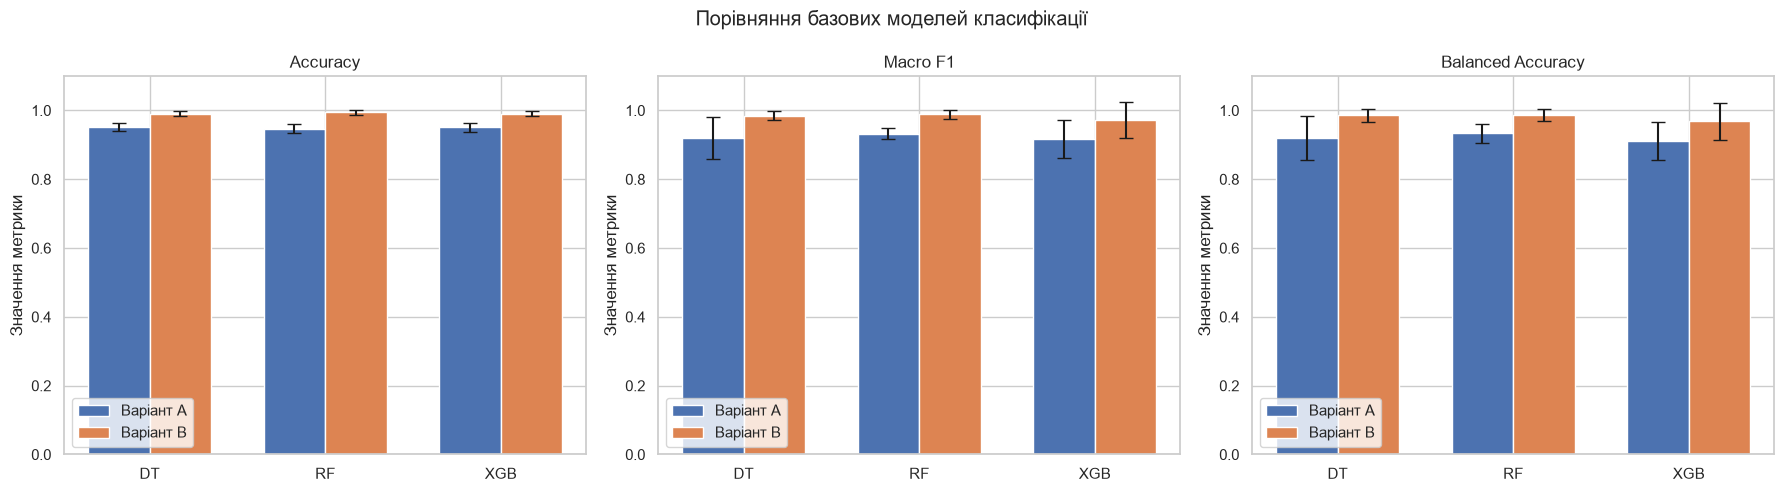

In [24]:
metric_labels = {
    "acc": "Accuracy",
    "f1m": "Macro F1",
    "bacc": "Balanced Accuracy"
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

positions = np.arange(len(MODEL_NAMES))
width = 0.35

for ax, (metric, label) in zip(
    axes, metric_labels.items()
):
    for i, variant in enumerate(["A", "B"]):

        subset = (
            baseline_df[
                baseline_df["Variant"] == variant
            ]
            .set_index("Model key")
            .loc[MODEL_NAMES]
        )

        ax.bar(
            positions + (i - 0.5) * width,
            subset[f"{metric}_mean"],
            width=width,
            yerr=subset[f"{metric}_std"],
            capsize=5,
            label=f"Варіант {variant}"
        )

    ax.set_title(label)
    ax.set_xticks(positions)
    ax.set_xticklabels(MODEL_NAMES)
    ax.set_ylim(0, 1.1)
    ax.set_ylabel("Значення метрики")
    ax.legend()

plt.suptitle(
    "Порівняння базових моделей класифікації"
)

plt.tight_layout()
plt.show()

### 3.7. Аналіз впливу індикаторів пропусків

Для кожної моделі визначимо зміну середнього
значення Macro F1 після додавання індикаторів
пропущених значень.

Додатна різниця свідчитиме про покращення якості,
від'ємна — про її погіршення.

Статистичну значущість отриманих відмінностей
буде перевірено на окремому етапі роботи.

In [25]:
indicator_effect = baseline_df.pivot(
    index="Model",
    columns="Variant",
    values="f1m_mean"
)

indicator_effect["Difference (B - A)"] = (
    indicator_effect["B"] - indicator_effect["A"]
)

indicator_effect["Relative change (%)"] = (
    indicator_effect["Difference (B - A)"] /
    indicator_effect["A"] * 100
)

display(indicator_effect.round(4))

best_baseline = baseline_df.loc[
    baseline_df["f1m_mean"].idxmax()
]

print("Найкраща базова модель:", best_baseline["Model"])
print("Варіант:", best_baseline["Variant"])
print(f"Macro F1: {best_baseline['f1m_mean']:.4f}")
print(f"Std: {best_baseline['f1m_std']:.4f}")

Variant,A,B,Difference (B - A),Relative change (%)
Model,,,,
Decision Tree,0.9206,0.9851,0.0645,7.0113
Random Forest,0.9329,0.9884,0.0555,5.9494
XGBoost,0.9168,0.9713,0.0545,5.9479


Найкраща базова модель: Random Forest
Варіант: B
Macro F1: 0.9884
Std: 0.0140


**Висновок.** За результатами повторної стратифікованої
крос-валідації встановлено, що додавання індикаторів
пропущених значень покращує всі три метрики оцінювання
для кожної досліджуваної моделі.

У варіанті A найкращий результат за Macro F1
продемонструвала модель Random Forest
(0.9329 ± 0.0163).

У варіанті B найкращою також стала модель Random Forest,
яка досягла Macro F1 = 0.9884 ± 0.0140,
Accuracy = 0.9940 та Balanced Accuracy = 0.9864.

Найбільше покращення Macro F1 після додавання
індикаторів пропусків отримано для Decision Tree:
на 0.0645, або 7.01% відносно початкового результату.

Для Random Forest та XGBoost відносне покращення
становить приблизно 5.95%.

Додавання індикаторів також зменшило стандартне
відхилення Macro F1 для всіх моделей, особливо
для Decision Tree — з 0.0610 до 0.0137.

Отримані результати узгоджуються з попереднім
статистичним аналізом залежності пропусків від класу.
Це свідчить про потенційну інформативність
самого факту відсутності значень.

Для подальшої оптимізації гіперпараметрів
використовуватимемо варіант B. Статистичну значущість
покращення перевіримо на наступних етапах роботи.

## 4. Оптимізація гіперпараметрів за допомогою Optuna

### 4.1. Визначення простору пошуку гіперпараметрів

Для покращення якості моделей виконаємо автоматичний
підбір гіперпараметрів за допомогою бібліотеки Optuna.

Оптимізація здійснюватиметься лише для варіанту B
з індикаторами пропущених значень.

Для пошуку використаємо алгоритм TPE
(Tree-structured Parzen Estimator), який враховує
результати попередніх випробувань для вибору
перспективних комбінацій гіперпараметрів.

Основною цільовою метрикою буде Macro F1.
Кількість випробувань для кожного дослідження — 30.

In [26]:
N_TRIALS = 30

optuna.logging.set_verbosity(optuna.logging.WARNING)


def suggest_params(trial, name):

    if name == "DT":
        return {
            "max_depth": trial.suggest_int(
                "max_depth", 2, 20
            ),
            "min_samples_split": trial.suggest_int(
                "min_samples_split", 2, 20
            ),
            "min_samples_leaf": trial.suggest_int(
                "min_samples_leaf", 1, 10
            ),
            "class_weight": trial.suggest_categorical(
                "class_weight", [None, "balanced"]
            )
        }

    if name == "RF":
        return {
            "n_estimators": trial.suggest_int(
                "n_estimators", 100, 500, step=50
            ),
            "max_depth": trial.suggest_int(
                "max_depth", 3, 30
            ),
            "min_samples_leaf": trial.suggest_int(
                "min_samples_leaf", 1, 10
            ),
            "max_features": trial.suggest_categorical(
                "max_features", ["sqrt", "log2", 0.5]
            ),
            "class_weight": trial.suggest_categorical(
                "class_weight",
                [None, "balanced", "balanced_subsample"]
            )
        }

    if name == "XGB":
        return {
            "n_estimators": trial.suggest_int(
                "n_estimators", 50, 400
            ),
            "max_depth": trial.suggest_int(
                "max_depth", 2, 10
            ),
            "learning_rate": trial.suggest_float(
                "learning_rate", 0.01, 0.3, log=True
            ),
            "subsample": trial.suggest_float(
                "subsample", 0.6, 1.0
            ),
            "colsample_bytree": trial.suggest_float(
                "colsample_bytree", 0.6, 1.0
            ),
            "min_child_weight": trial.suggest_float(
                "min_child_weight", 1.0, 10.0, log=True
            )
        }

    raise ValueError(f"Unknown model: {name}")

### 4.2. Реалізація цільової функції Optuna

Для кожного випробування Optuna формуватиме
комбінацію гіперпараметрів і створюватиме повний
пайплайн попередньої обробки та класифікації.

Оцінювання здійснюватиметься за допомогою
3-блочної стратифікованої крос-валідації.

Цільова функція повертатиме середнє значення
Macro F1, яке Optuna намагатиметься максимізувати.

Включення попередньої обробки до пайплайна
забезпечує відсутність витоку даних.

In [27]:
def optimize_model(name, X_data, y_data):

    inner_cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=SEED
    )

    inner_splits = list(
        inner_cv.split(X_data, y_data)
    )

    def objective(trial):

        params = suggest_params(trial, name)

        pipeline = build_pipeline(
            name,
            with_indicators=True,
            params=params
        )

        scores = cross_val_score(
            pipeline,
            X_data,
            y_data,
            cv=inner_splits,
            scoring="f1_macro",
            n_jobs=1,
            error_score="raise"
        )

        return scores.mean()

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=SEED
        )
    )

    study.optimize(
        objective,
        n_trials=N_TRIALS,
        n_jobs=1
    )

    return study

### 4.3. Вкладена крос-валідація (Nested Cross-Validation)

Для зменшення оптимістичного зміщення оцінок
застосуємо вкладену крос-валідацію.

Зовнішній цикл складається з п'яти стратифікованих
блоків, а внутрішній — із трьох.

У внутрішньому циклі здійснюється оптимізація
гіперпараметрів за допомогою Optuna.

Після визначення найкращих гіперпараметрів модель
навчається на всьому тренувальному наборі зовнішнього
блоку та оцінюється на його валідаційній частині.

Таким чином, дані зовнішнього валідаційного блоку
не використовуються для вибору гіперпараметрів.

In [28]:
nested_results = {}
nested_summary = []
nested_studies = {}

outer_splits = list(
    outer.split(X_train, y_train)
)

for name in MODEL_NAMES:

    print(f"\nМодель: {MODEL_LABELS[name]}")

    fold_scores = []
    fold_studies = []

    start = time.perf_counter()

    for fold, (tr_idx, va_idx) in enumerate(
        outer_splits, start=1
    ):

        X_outer_train = X_train.iloc[tr_idx]
        X_outer_val = X_train.iloc[va_idx]

        y_outer_train = y_train[tr_idx]
        y_outer_val = y_train[va_idx]

        study = optimize_model(
            name,
            X_outer_train,
            y_outer_train
        )

        pipeline = build_pipeline(
            name,
            with_indicators=True,
            params=study.best_params
        )

        pipeline.fit(
            X_outer_train,
            y_outer_train
        )

        predictions = pipeline.predict(X_outer_val)

        score = f1_score(
            y_outer_val,
            predictions,
            average="macro",
            zero_division=0
        )

        fold_scores.append(score)
        fold_studies.append(study)

        print(
            f"Fold {fold}: "
            f"Inner F1 = {study.best_value:.4f}, "
            f"Outer F1 = {score:.4f}"
        )

    elapsed = time.perf_counter() - start

    nested_results[name] = np.array(fold_scores)
    nested_studies[name] = fold_studies

    nested_summary.append({
        "Model": MODEL_LABELS[name],
        "Model key": name,
        "Nested F1 mean": np.mean(fold_scores),
        "Nested F1 std": np.std(fold_scores, ddof=1),
        "Time (s)": elapsed
    })

    print(
        f"Nested Macro F1: "
        f"{np.mean(fold_scores):.4f} "
        f"± {np.std(fold_scores, ddof=1):.4f}"
    )

    print(f"Час виконання: {elapsed:.2f} с")

nested_df = pd.DataFrame(nested_summary)

display(nested_df.round(4))


Модель: Decision Tree
Fold 1: Inner F1 = 0.9672, Outer F1 = 0.9837
Fold 2: Inner F1 = 0.9464, Outer F1 = 0.9728
Fold 3: Inner F1 = 0.9460, Outer F1 = 0.9809
Fold 4: Inner F1 = 0.9612, Outer F1 = 0.9610
Fold 5: Inner F1 = 0.8335, Outer F1 = 1.0000
Nested Macro F1: 0.9797 ± 0.0144
Час виконання: 14.46 с

Модель: Random Forest
Fold 1: Inner F1 = 0.9747, Outer F1 = 1.0000
Fold 2: Inner F1 = 0.9865, Outer F1 = 0.9857
Fold 3: Inner F1 = 0.9756, Outer F1 = 1.0000
Fold 4: Inner F1 = 0.9622, Outer F1 = 0.9739
Fold 5: Inner F1 = 0.9253, Outer F1 = 0.9809
Nested Macro F1: 0.9881 ± 0.0116
Час виконання: 399.57 с

Модель: XGBoost
Fold 1: Inner F1 = 0.9742, Outer F1 = 0.9837
Fold 2: Inner F1 = 0.9883, Outer F1 = 0.9857
Fold 3: Inner F1 = 0.9707, Outer F1 = 1.0000
Fold 4: Inner F1 = 0.9523, Outer F1 = 0.9673
Fold 5: Inner F1 = 0.9199, Outer F1 = 0.9809
Nested Macro F1: 0.9835 ± 0.0117
Час виконання: 489.88 с


,Model,Model key,Nested F1 mean,Nested F1 std,Time (s)
0,Decision Tree,DT,0.9797,0.0144,14.4620
1,Random Forest,RF,0.9881,0.0116,399.5674
2,XGBoost,XGB,0.9835,0.0117,489.8767


### 4.4. Оптимізація на всій тренувальній вибірці

Після завершення вкладеної крос-валідації виконаємо
окрему оптимізацію гіперпараметрів кожної моделі
на всій тренувальній вибірці.

Отримані гіперпараметри використовуватимуться
для навчання фінальних моделей.

Значення best_value порівняємо з незалежними
оцінками вкладеної крос-валідації для дослідження
можливого оптимістичного зміщення.

In [29]:
final_studies = {}
final_params = {}
optimization_summary = []

for name in MODEL_NAMES:

    print(f"\nОптимізація: {MODEL_LABELS[name]}")

    start = time.perf_counter()

    study = optimize_model(
        name,
        X_train,
        y_train
    )

    elapsed = time.perf_counter() - start

    final_studies[name] = study
    final_params[name] = study.best_params

    optimization_summary.append({
        "Model": MODEL_LABELS[name],
        "Model key": name,
        "Optuna best F1": study.best_value,
        "Best trial": study.best_trial.number,
        "Time (s)": elapsed
    })

    print(f"Best Macro F1: {study.best_value:.4f}")
    print("Best parameters:", study.best_params)
    print(f"Час виконання: {elapsed:.2f} с")

optimization_df = pd.DataFrame(
    optimization_summary
)

display(optimization_df.round(4))


Оптимізація: Decision Tree
Best Macro F1: 0.8879
Best parameters: {'max_depth': 8, 'min_samples_split': 8, 'min_samples_leaf': 2, 'class_weight': None}
Час виконання: 2.74 с

Оптимізація: Random Forest
Best Macro F1: 0.9231
Best parameters: {'n_estimators': 150, 'max_depth': 25, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': None}
Час виконання: 58.99 с

Оптимізація: XGBoost
Best Macro F1: 0.9157
Best parameters: {'n_estimators': 109, 'max_depth': 7, 'learning_rate': 0.07716496058783939, 'subsample': 0.7113887694723978, 'colsample_bytree': 0.8913671798231982, 'min_child_weight': 1.1186254641702897}
Час виконання: 66.38 с


,Model,Model key,Optuna best F1,Best trial,Time (s)
0,Decision Tree,DT,0.8879,2,2.7408
1,Random Forest,RF,0.9231,10,58.9924
2,XGBoost,XGB,0.9157,19,66.3766


### 4.5. Порівняння звичайної та вкладеної крос-валідації

Порівняємо найкраще значення цільової функції Optuna
з оцінкою вкладеної крос-валідації.

Значення best_value може бути оптимістично зміщеним,
оскільки ті самі валідаційні блоки використовуються
для оцінювання та вибору найкращих гіперпараметрів.

Вкладена крос-валідація дозволяє оцінити процедуру
навчання та оптимізації на незалежних зовнішніх блоках.

In [30]:
nested_comparison = nested_df.merge(
    optimization_df[
        ["Model key", "Optuna best F1"]
    ],
    on="Model key"
)

nested_comparison["Difference"] = (
    nested_comparison["Optuna best F1"] -
    nested_comparison["Nested F1 mean"]
)

print(
    "Таблиця 3. Порівняння звичайної "
    "та вкладеної крос-валідації"
)

display(
    nested_comparison[[
        "Model",
        "Nested F1 mean",
        "Nested F1 std",
        "Optuna best F1",
        "Difference"
    ]].round(4)
)

Таблиця 3. Порівняння звичайної та вкладеної крос-валідації


,Model,Nested F1 mean,Nested F1 std,Optuna best F1,Difference
0,Decision Tree,0.9797,0.0144,0.8879,-0.0918
1,Random Forest,0.9881,0.0116,0.9231,-0.0650
2,XGBoost,0.9835,0.0117,0.9157,-0.0679


**Висновок.** За результатами вкладеної крос-валідації
найкращою моделлю стала Random Forest із середнім
Macro F1 = 0.9881 та стандартним відхиленням 0.0116.

XGBoost отримав Macro F1 = 0.9835 ± 0.0117,
а Decision Tree — 0.9797 ± 0.0144.

Для всіх трьох моделей значення Optuna best_value
виявилися нижчими за оцінки вкладеної крос-валідації.

Це може пояснюватися різними схемами поділу даних,
розмірами тренувальних блоків та малою кількістю
спостережень рідкісного класу 1.

Хоча вибір найкращого випробування Optuna може
спричиняти оптимістичне зміщення, у цьому експерименті
воно не проявилося у вигляді перевищення оцінки
вкладеної крос-валідації.

Вкладена крос-валідація залишається методологічно
коректнішим способом оцінювання процедури
оптимізації гіперпараметрів.

### 4.6. Найкращі гіперпараметри моделей

Представимо найкращі комбінації гіперпараметрів,
отримані в результаті оптимізації на всій
тренувальній вибірці.

In [34]:
params_table = pd.DataFrame({
    MODEL_LABELS[name]: pd.Series({
        key: str(value)
        for key, value in final_params[name].items()
    })
    for name in MODEL_NAMES
})

print("Таблиця 4. Найкращі гіперпараметри моделей")

display(params_table.fillna("—"))

Таблиця 4. Найкращі гіперпараметри моделей


,Decision Tree,Random Forest,XGBoost
class_weight,None,None,—
colsample_bytree,—,—,0.8913671798231982
learning_rate,—,—,0.07716496058783939
max_depth,8,25,7
max_features,—,sqrt,—
min_child_weight,—,—,1.1186254641702897
min_samples_leaf,2,1,—
min_samples_split,8,—,—
n_estimators,—,150,109
subsample,—,—,0.7113887694723978


### 4.7. Візуалізація процесу оптимізації

Для кожної моделі побудуємо два графіки:

- Optimization History — зміна значення цільової
  функції протягом випробувань Optuna.
- Parameter Importances — оцінка відносного впливу
  гіперпараметрів на значення цільової функції.

Графіки дозволять проаналізувати збіжність процесу
оптимізації та визначити найбільш впливові
гіперпараметри кожної моделі.

C:\Users\YURII\AppData\Local\Temp\ipykernel_22296\1304623620.py:10: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_optimization_history(study)


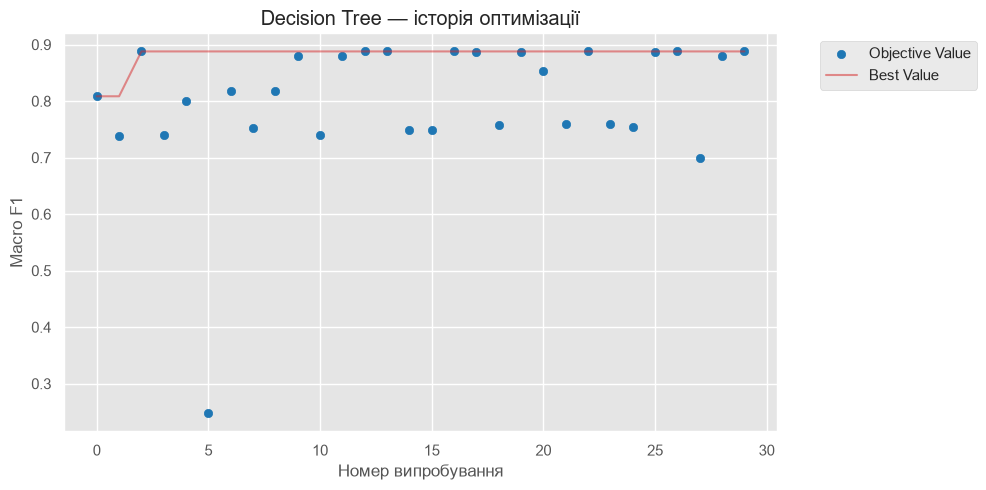

C:\Users\YURII\AppData\Local\Temp\ipykernel_22296\1304623620.py:24: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_param_importances(study)


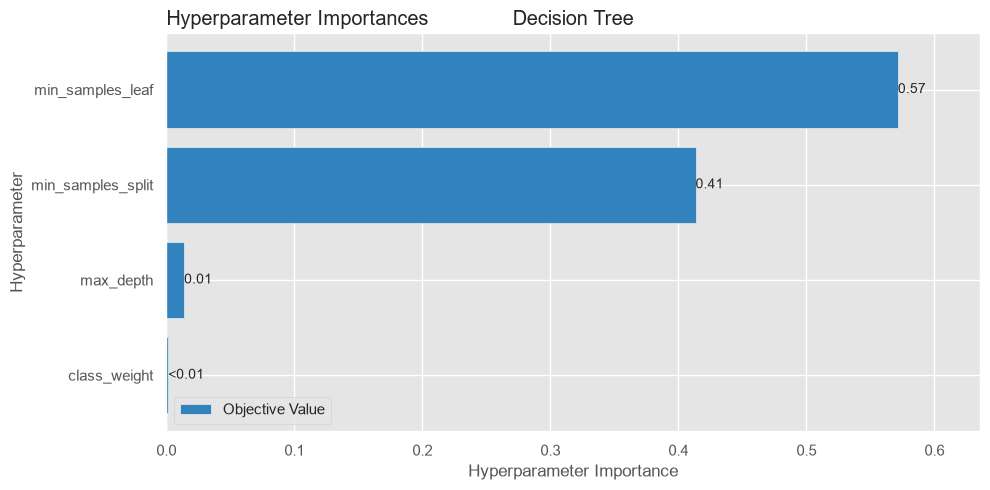

C:\Users\YURII\AppData\Local\Temp\ipykernel_22296\1304623620.py:10: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_optimization_history(study)


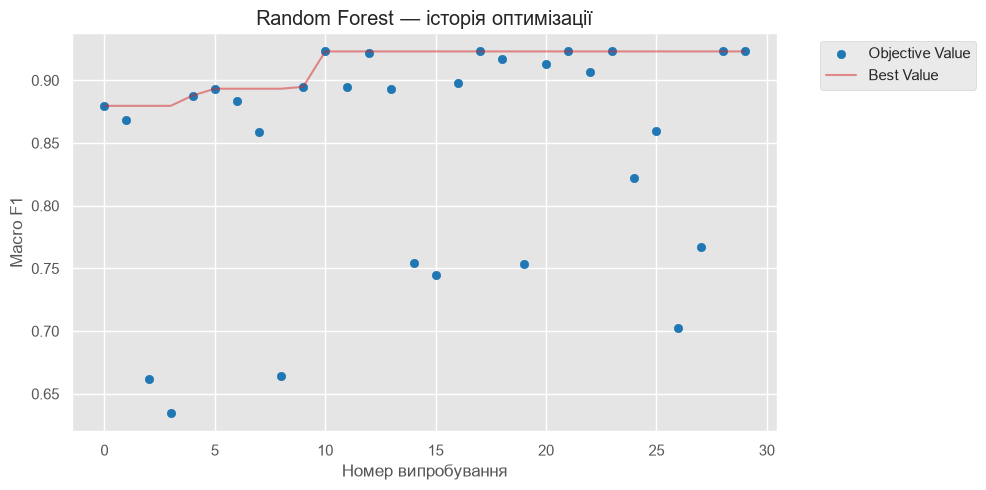

C:\Users\YURII\AppData\Local\Temp\ipykernel_22296\1304623620.py:24: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_param_importances(study)


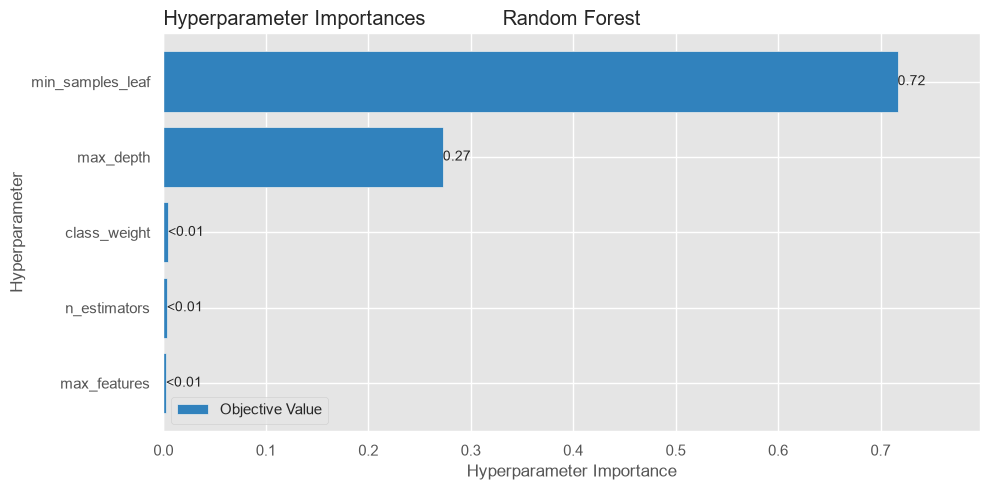

C:\Users\YURII\AppData\Local\Temp\ipykernel_22296\1304623620.py:10: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_optimization_history(study)


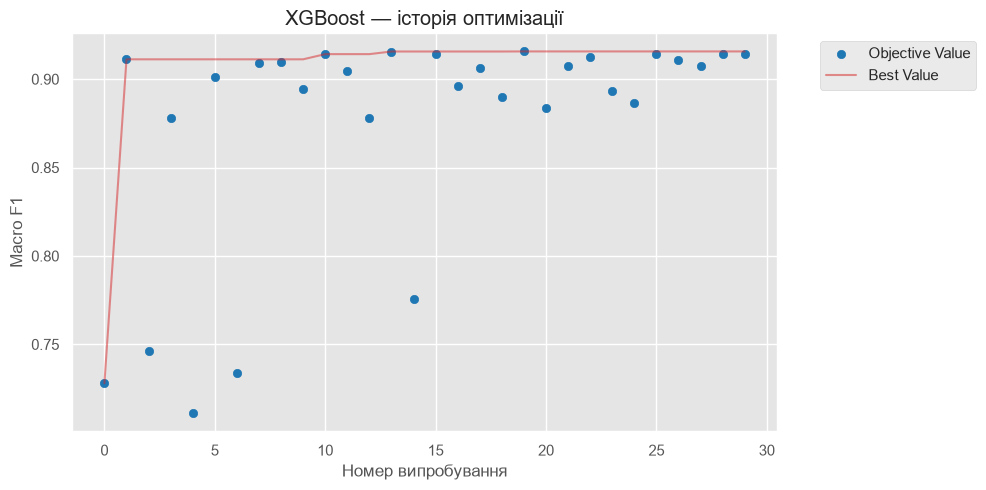

C:\Users\YURII\AppData\Local\Temp\ipykernel_22296\1304623620.py:24: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_param_importances(study)


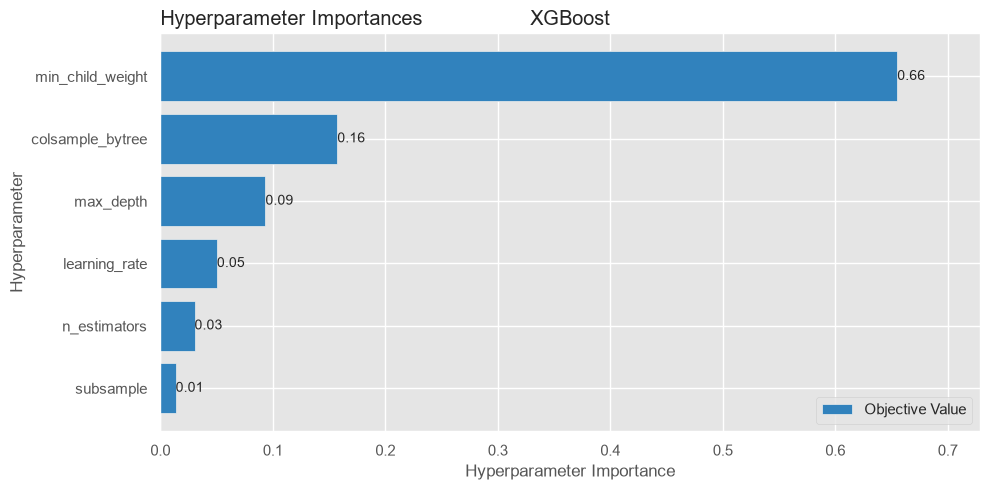

In [33]:
from optuna.visualization.matplotlib import (
    plot_optimization_history,
    plot_param_importances
)

for name in MODEL_NAMES:

    study = final_studies[name]

    ax = plot_optimization_history(study)

    ax.set_title(
        f"{MODEL_LABELS[name]} — історія оптимізації"
    )

    ax.set_xlabel("Номер випробування")
    ax.set_ylabel("Macro F1")

    ax.figure.set_size_inches(10, 5)

    plt.tight_layout()
    plt.show()

    ax = plot_param_importances(study)

    ax.set_title(
        f"{MODEL_LABELS[name]}"
    )

    ax.figure.set_size_inches(10, 5)

    plt.tight_layout()
    plt.show()

**Висновок.** За графіками історії оптимізації
встановлено, що найкращі значення цільової функції
було знайдено протягом перших 20 випробувань.

Для Decision Tree найважливішими гіперпараметрами
виявилися min_samples_leaf (0.57) та
min_samples_split (0.41).

Для Random Forest найбільший вплив мали
min_samples_leaf (0.72) та max_depth (0.27).

Для XGBoost найбільш впливовим гіперпараметром
став min_child_weight (0.66), після якого
розташувалися colsample_bytree (0.16)
та max_depth (0.09).

Отримані результати свідчать про важливість
гіперпараметрів, які контролюють складність дерев
та можливість формування малих листових вузлів.

Це особливо актуально для класифікації рідкісних
класів, які представлені малою кількістю об'єктів.

За описовим порівнянням із базовими моделями
найбільший приріст Macro F1 отримано для XGBoost:
з 0.9713 до 0.9835. Однак через різні схеми
крос-валідації цей приріст не можна однозначно
приписати лише оптимізації гіперпараметрів.

## 5. Статистичне порівняння моделей

### 5.1. Скоригований t-критерій Nadeau–Bengio

Оцінки, отримані під час повторної крос-валідації,
не є незалежними, оскільки тренувальні вибірки
різних блоків частково перетинаються.

Тому для статистичного порівняння моделей
використаємо скоригований парний t-критерій
Nadeau–Bengio.

Нульова гіпотеза H0: середня різниця між
результатами двох моделей дорівнює нулю.

Альтернативна гіпотеза H1: середня різниця
між результатами моделей відрізняється від нуля.

Рівень статистичної значущості alpha = 0.05.

In [35]:
def corrected_t_test(scores_a, scores_b, cv_splits):

    scores_a = np.asarray(scores_a)
    scores_b = np.asarray(scores_b)

    differences = scores_b - scores_a

    n = len(differences)

    mean_diff = differences.mean()
    variance = differences.var(ddof=1)

    ratio = np.mean([
        len(val_idx) / len(train_idx)
        for train_idx, val_idx in cv_splits
    ])

    correction = 1 / n + ratio

    standard_error = np.sqrt(
        correction * variance
    )

    if standard_error == 0:
        t_stat = (
            0.0 if mean_diff == 0
            else np.sign(mean_diff) * np.inf
        )
    else:
        t_stat = mean_diff / standard_error

    df = n - 1

    p_value = 2 * stats.t.sf(
        abs(t_stat), df=df
    )

    return {
        "Mean difference": mean_diff,
        "t-statistic": t_stat,
        "p-value": p_value,
        "Significant": p_value < ALPHA
    }

### 5.2. Статистичне порівняння варіантів A та B

Для кожної базової моделі порівняємо 15 парних
значень Macro F1, отриманих на однакових блоках
повторної стратифікованої крос-валідації.

Це дозволить визначити, чи є покращення після
додавання індикаторів пропусків статистично
значущим.

In [36]:
statistical_results = []

for name in MODEL_NAMES:

    scores_a = baseline_results[
        ("A", name)
    ]["test_f1m"]

    scores_b = baseline_results[
        ("B", name)
    ]["test_f1m"]

    result = corrected_t_test(
        scores_a,
        scores_b,
        cv_splits
    )

    statistical_results.append({
        "Comparison": f"{name}: B - A",
        **result
    })

    print(f"\nМодель: {MODEL_LABELS[name]}")

    print(
        f"Середня різниця: "
        f"{result['Mean difference']:.6f}"
    )

    print(
        f"t-statistic: "
        f"{result['t-statistic']:.6f}"
    )

    print(f"p-value: {result['p-value']:.6f}")

    print(
        "Статистично значуща різниця"
        if result["Significant"]
        else "Статистично значущої різниці не виявлено"
    )


Модель: Decision Tree
Середня різниця: 0.064546
t-statistic: 1.874177
p-value: 0.081927
Статистично значущої різниці не виявлено

Модель: Random Forest
Середня різниця: 0.055500
t-statistic: 4.929104
p-value: 0.000222
Статистично значуща різниця

Модель: XGBoost
Середня різниця: 0.054528
t-statistic: 2.457443
p-value: 0.027645
Статистично значуща різниця


### 5.3. Порівняння двох найкращих базових моделей

Для визначення статистичної значущості переваги
найкращої моделі порівняємо дві моделі варіанту B,
які отримали найбільші середні значення Macro F1.

Порівняння здійснюватиметься за допомогою
скоригованого t-критерію Nadeau–Bengio на
однакових блоках крос-валідації.

In [37]:
top_two = (
    baseline_df[baseline_df["Variant"] == "B"]
    .sort_values("f1m_mean", ascending=False)
    .head(2)
)

best_name = top_two.iloc[0]["Model key"]
second_name = top_two.iloc[1]["Model key"]

print("Найкраща модель:", MODEL_LABELS[best_name])
print("Друга модель:", MODEL_LABELS[second_name])

scores_best = baseline_results[
    ("B", best_name)
]["test_f1m"]

scores_second = baseline_results[
    ("B", second_name)
]["test_f1m"]

result = corrected_t_test(
    scores_second,
    scores_best,
    cv_splits
)

statistical_results.append({
    "Comparison": f"{best_name} - {second_name} (B)",
    **result
})

print(f"\nСередня різниця: {result['Mean difference']:.6f}")
print(f"t-statistic: {result['t-statistic']:.6f}")
print(f"p-value: {result['p-value']:.6f}")

Найкраща модель: Random Forest
Друга модель: Decision Tree

Середня різниця: 0.003227
t-statistic: 0.301308
p-value: 0.767608


### 5.4. Результати статистичного порівняння

Представимо результати всіх чотирьох статистичних
порівнянь у вигляді таблиці.

Якщо p-value < 0.05, нульова гіпотеза відхиляється.
В іншому випадку недостатньо підстав для її відхилення.

Відсутність статистично значущої різниці не означає,
що моделі є повністю еквівалентними.

Результати інтерпретуються для кожного порівняння
окремо, без корекції на множинні перевірки гіпотез.

In [38]:
statistical_df = pd.DataFrame(
    statistical_results
)

statistical_df["Conclusion"] = np.where(
    statistical_df["Significant"],
    "Відхиляємо H0",
    "Не відхиляємо H0"
)

print("Таблиця 5. Статистичне порівняння моделей")

display(statistical_df.round(6))

Таблиця 5. Статистичне порівняння моделей


,Comparison,Mean difference,t-statistic,p-value,Significant,Conclusion
0,DT: B - A,0.064546,1.874177,0.081927,False,Не відхиляємо H0
1,RF: B - A,0.055500,4.929104,0.000222,True,Відхиляємо H0
2,XGB: B - A,0.054528,2.457443,0.027645,True,Відхиляємо H0
3,RF - DT (B),0.003227,0.301308,0.767608,False,Не відхиляємо H0


### 5.5. Візуалізація парних різниць Macro F1

Побудуємо діаграму розподілу парних різниць
Macro F1 для кожного статистичного порівняння.

Додатні значення відповідають перевазі варіанту B
над варіантом A або найкращої моделі над другою.

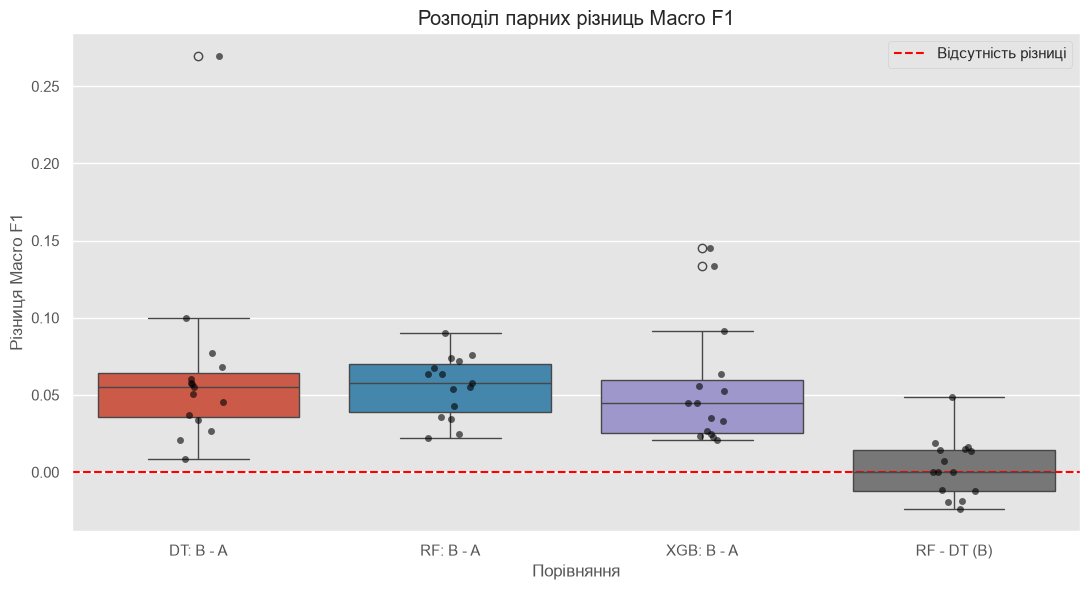

In [39]:
paired_differences = {}

for name in MODEL_NAMES:

    paired_differences[f"{name}: B - A"] = (
        baseline_results[("B", name)]["test_f1m"] -
        baseline_results[("A", name)]["test_f1m"]
    )

paired_differences[
    f"{best_name} - {second_name} (B)"
] = scores_best - scores_second

differences_df = pd.DataFrame(paired_differences)

plt.figure(figsize=(11, 6))

sns.boxplot(data=differences_df)

sns.stripplot(
    data=differences_df,
    color="black",
    alpha=0.6,
    jitter=0.1
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
    label="Відсутність різниці"
)

plt.title("Розподіл парних різниць Macro F1")
plt.ylabel("Різниця Macro F1")
plt.xlabel("Порівняння")
plt.legend()
plt.tight_layout()
plt.show()

**Висновок.** За допомогою скоригованого t-критерію
Nadeau–Bengio проведено статистичне порівняння моделей
на рівні значущості 0.05.

Для Random Forest (p = 0.000222) та XGBoost
(p = 0.027645) підтверджено статистично значуще
покращення Macro F1 після додавання індикаторів
пропущених значень.

Для Decision Tree, незважаючи на найбільший середній
приріст Macro F1 (0.064546), статистично значущого
покращення не підтверджено (p = 0.081927).
Це пояснюється значною варіативністю парних різниць.

Порівняння Random Forest та Decision Tree у варіанті B
не виявило статистично значущої різниці
(p = 0.767608).

Таким чином, хоча Random Forest має найвище середнє
значення Macro F1, її статистично значущу перевагу
над Decision Tree не підтверджено.

Результати наведено без корекції на множинні
перевірки гіпотез.

## 6. Навчання та оцінювання фінальних моделей

### 6.1. Навчання фінальних моделей

Навчимо Decision Tree, Random Forest та XGBoost
на всій тренувальній вибірці, використовуючи
найкращі гіперпараметри, отримані за допомогою Optuna.

Для всіх моделей застосуємо варіант B попередньої
обробки з індикаторами пропущених значень.

Збережемо навчені пайплайни у вигляді артефактів
за допомогою бібліотеки joblib.

Збереження повного пайплайна дозволяє надалі
виконувати прогнозування на початкових даних
без повторного навчання та ручної обробки ознак.

In [40]:
final_models = {}
final_training_results = []

for name in MODEL_NAMES:

    print(f"\nНавчання: {MODEL_LABELS[name]}")

    pipeline = build_pipeline(
        name,
        with_indicators=True,
        params=final_params[name]
    )

    start = time.perf_counter()

    pipeline.fit(X_train, y_train)

    elapsed = time.perf_counter() - start

    final_models[name] = pipeline

    model_path = Path("artifacts") / f"{name.lower()}_pipeline.joblib"

    joblib.dump(pipeline, model_path)

    final_training_results.append({
        "Model": MODEL_LABELS[name],
        "Training time (s)": elapsed,
        "Artifact": str(model_path),
        "Size (KB)": model_path.stat().st_size / 1024
    })

    print(f"Час навчання: {elapsed:.4f} с")
    print(f"Модель збережено: {model_path}")

joblib.dump(
    label_encoder,
    "artifacts/label_encoder.joblib"
)

final_training_df = pd.DataFrame(
    final_training_results
)

display(final_training_df.round(4))


Навчання: Decision Tree
Час навчання: 0.0245 с
Модель збережено: artifacts\dt_pipeline.joblib

Навчання: Random Forest
Час навчання: 0.3018 с
Модель збережено: artifacts\rf_pipeline.joblib

Навчання: XGBoost
Час навчання: 0.1844 с
Модель збережено: artifacts\xgb_pipeline.joblib


,Model,Training time (s),Artifact,Size (KB)
0,Decision Tree,0.0245,artifacts\dt_pipeline.joblib,14.3086
1,Random Forest,0.3018,artifacts\rf_pipeline.joblib,1651.1592
2,XGBoost,0.1844,artifacts\xgb_pipeline.joblib,514.8467


### 6.2. Оцінювання на незалежній тестовій вибірці

Виконаємо прогнозування для 180 спостережень
тестової вибірки, яка не використовувалася
під час навчання та оптимізації гіперпараметрів.

Для кожної моделі розрахуємо Accuracy, Macro F1
та Balanced Accuracy.

Отримані результати дозволять оцінити здатність
моделей узагальнювати закономірності на нових даних.

In [41]:
test_predictions = {}
test_probabilities = {}
test_results = []

for name in MODEL_NAMES:

    pipeline = final_models[name]

    start = time.perf_counter()

    y_pred = pipeline.predict(X_test)

    elapsed = time.perf_counter() - start

    test_predictions[name] = y_pred

    test_probabilities[name] = pipeline.predict_proba(
        X_test
    )

    test_results.append({
        "Model": MODEL_LABELS[name],
        "Model key": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, y_pred
        ),
        "Correct predictions": (y_test == y_pred).sum(),
        "Incorrect predictions": (y_test != y_pred).sum(),
        "Prediction time (s)": elapsed
    })

test_df = pd.DataFrame(test_results)

print("Таблиця 6. Результати на тестовій вибірці")

display(
    test_df.drop(columns="Model key").round(4)
)

Таблиця 6. Результати на тестовій вибірці


,Model,Accuracy,Macro F1,Balanced Accuracy,Correct predictions,Incorrect predictions,Prediction time (s)
0,Decision Tree,0.9778,0.9076,0.8721,176,4,0.0118
1,Random Forest,0.9944,0.9326,0.9000,179,1,0.0369
2,XGBoost,0.9889,0.9270,0.8985,178,2,0.0103


### 6.3. Визначення найкращої фінальної моделі

Порівняємо фінальні моделі за основною метрикою
Macro F1 та визначимо модель, яка продемонструвала
найкращий результат на незалежній тестовій вибірці.

Також порівняємо тестові результати з оцінками
вкладеної крос-валідації.

Таке порівняння має описовий характер і не
використовується для повторного підбору
гіперпараметрів.

In [42]:
best_test_row = test_df.loc[
    test_df["Macro F1"].idxmax()
]

best_test_name = best_test_row["Model key"]

print("Найкраща тестова модель:", best_test_row["Model"])
print(f"Accuracy: {best_test_row['Accuracy']:.4f}")
print(f"Macro F1: {best_test_row['Macro F1']:.4f}")
print(
    f"Balanced Accuracy: "
    f"{best_test_row['Balanced Accuracy']:.4f}"
)

test_comparison = nested_df.merge(
    test_df[["Model key", "Macro F1"]],
    on="Model key"
)

test_comparison["Difference (Test - Nested)"] = (
    test_comparison["Macro F1"] -
    test_comparison["Nested F1 mean"]
)

display(
    test_comparison[[
        "Model",
        "Nested F1 mean",
        "Macro F1",
        "Difference (Test - Nested)"
    ]].round(4)
)

Найкраща тестова модель: Random Forest
Accuracy: 0.9944
Macro F1: 0.9326
Balanced Accuracy: 0.9000


,Model,Nested F1 mean,Macro F1,Difference (Test - Nested)
0,Decision Tree,0.9797,0.9076,-0.0721
1,Random Forest,0.9881,0.9326,-0.0555
2,XGBoost,0.9835,0.9270,-0.0565


### 6.4. Візуалізація результатів фінальних моделей

Побудуємо групову стовпчикову діаграму для
порівняння Accuracy, Macro F1 та Balanced Accuracy
фінальних моделей на тестовій вибірці.

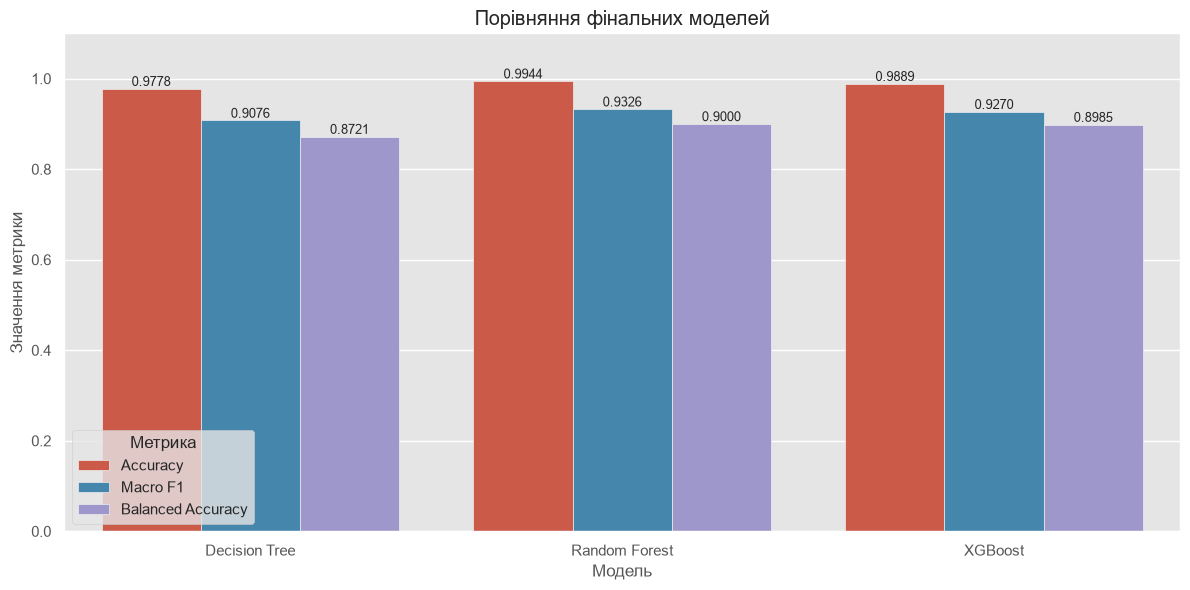

In [44]:
test_plot_df = test_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Macro F1",
        "Balanced Accuracy"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=test_plot_df,
    x="Model",
    y="Score",
    hue="Metric"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f",
        fontsize=9
    )

plt.title("Порівняння фінальних моделей")
plt.xlabel("Модель")
plt.ylabel("Значення метрики")
plt.ylim(0, 1.1)
plt.legend(title="Метрика")
plt.tight_layout()
plt.show()

### 6.5. Детальний звіт класифікації

Для моделі з найвищим тестовим Macro F1 сформуємо
детальний звіт класифікації за допомогою
classification_report.

Для кожного класу визначимо:

- Precision — частка правильних прогнозів серед
  усіх прогнозів відповідного класу.
- Recall — частка правильно розпізнаних об'єктів
  серед усіх об'єктів відповідного класу.
- F1-score — гармонійне середнє Precision та Recall.
- Support — фактична кількість об'єктів класу.

Особливу увагу приділимо якості класифікації
рідкісних класів.

In [45]:
best_test_predictions = test_predictions[
    best_test_name
]

class_names = label_encoder.classes_.astype(str)

report = classification_report(
    y_test,
    best_test_predictions,
    labels=np.arange(N_CLASSES),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report).T

print(
    "Детальний звіт:",
    MODEL_LABELS[best_test_name]
)

display(report_df.round(4))

Детальний звіт: Random Forest


,precision,recall,f1-score,support
1,1.0000,0.5000,0.6667,2.0000
2,1.0000,1.0000,1.0000,20.0000
3,0.9928,1.0000,0.9964,137.0000
5,1.0000,1.0000,1.0000,13.0000
U,1.0000,1.0000,1.0000,8.0000
accuracy,0.9944,0.9944,0.9944,0.9944
macro avg,0.9986,0.9000,0.9326,180.0000
weighted avg,0.9945,0.9944,0.9935,180.0000


### 6.6. Побудова матриць помилок

Для детального аналізу помилок класифікації
побудуємо абсолютну та нормалізовану за рядками
матриці помилок.

Рядки матриці відповідають фактичним класам,
а стовпці — прогнозованим.

Елементи головної діагоналі характеризують
правильні прогнози, а позадіагональні елементи
відображають помилки класифікації.

Нормалізація за рядками дозволяє порівнювати
якість розпізнавання класів незалежно від
кількості їхніх спостережень.

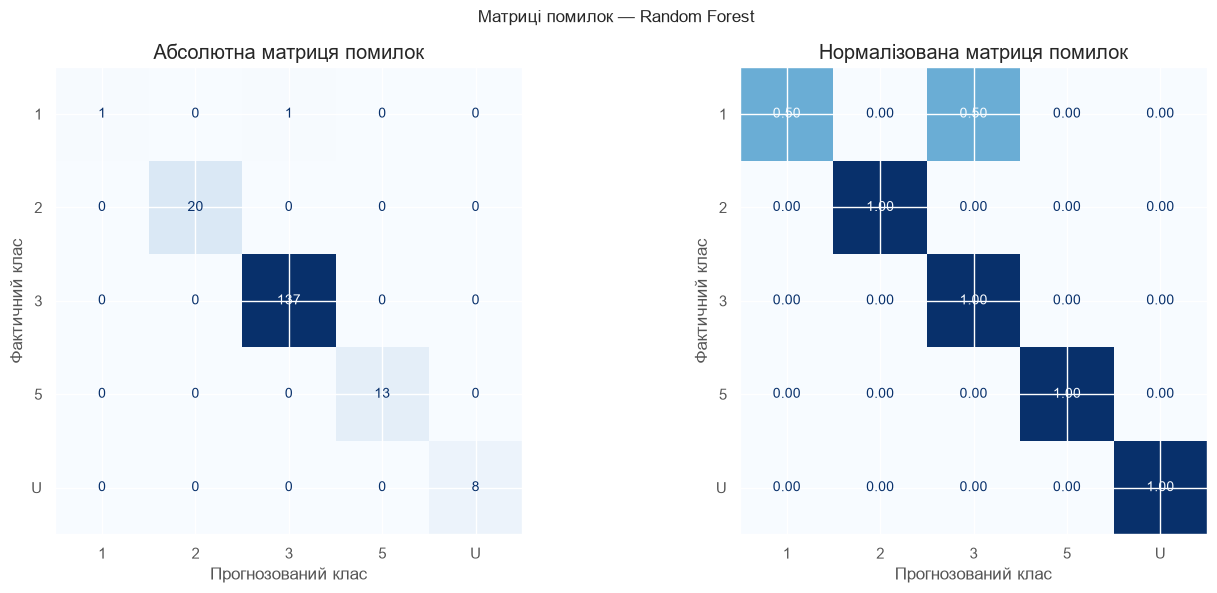

In [46]:
cm_absolute = confusion_matrix(
    y_test,
    best_test_predictions,
    labels=np.arange(N_CLASSES)
)

cm_normalized = confusion_matrix(
    y_test,
    best_test_predictions,
    labels=np.arange(N_CLASSES),
    normalize="true"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm_absolute,
    display_labels=class_names
).plot(
    ax=axes[0],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

axes[0].set_title("Абсолютна матриця помилок")

ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=class_names
).plot(
    ax=axes[1],
    cmap="Blues",
    values_format=".2f",
    colorbar=False
)

axes[1].set_title("Нормалізована матриця помилок")

for ax in axes:
    ax.set_xlabel("Прогнозований клас")
    ax.set_ylabel("Фактичний клас")

plt.suptitle(
    f"Матриці помилок — {MODEL_LABELS[best_test_name]}"
)

plt.tight_layout()
plt.show()

### 6.7. Аналіз помилково класифікованих об'єктів

Визначимо об'єкти тестової вибірки, для яких
найкраща тестова модель сформувала неправильний
прогноз.

Порівняємо фактичні та прогнозовані класи,
а також визначимо класи з найнижчими
значеннями Recall та F1-score.

In [47]:
errors_mask = y_test != best_test_predictions

errors_df = pd.DataFrame({
    "Object index": X_test.index[errors_mask],

    "True class": label_encoder.inverse_transform(
        y_test[errors_mask]
    ),

    "Predicted class": label_encoder.inverse_transform(
        best_test_predictions[errors_mask]
    ),

    "Confidence": test_probabilities[
        best_test_name
    ][errors_mask].max(axis=1)
})

print("Кількість помилок:", errors_mask.sum())

display(errors_df.round(4))

class_performance = report_df.loc[
    class_names,
    ["precision", "recall", "f1-score", "support"]
].sort_values("f1-score")

print("Якість класифікації окремих класів:")

display(class_performance.round(4))

Кількість помилок: 1


,Object index,True class,Predicted class,Confidence
0,24,1,3,0.8


Якість класифікації окремих класів:


,precision,recall,f1-score,support
1,1.0000,0.5,0.6667,2.0
3,0.9928,1.0,0.9964,137.0
2,1.0000,1.0,1.0000,20.0
5,1.0000,1.0,1.0000,13.0
U,1.0000,1.0,1.0000,8.0


**Висновок.** Усі три фінальні моделі успішно навчені
на тренувальній вибірці та збережені у форматі joblib.

Найкращий результат на незалежній тестовій вибірці
продемонструвала Random Forest:
Accuracy = 0.9944, Macro F1 = 0.9326,
Balanced Accuracy = 0.9000.

Модель правильно класифікувала 179 зі 180 об'єктів.
Єдиною помилкою стало віднесення об'єкта класу 1
з індексом 24 до класу 3.

Найскладнішим для класифікації виявився клас 1,
для якого Recall становить 0.5, а F1-score — 0.6667.
Усі об'єкти інших класів розпізнано правильно.

Для всіх моделей тестове значення Macro F1 виявилося
нижчим за середню оцінку вкладеної крос-валідації.
Однією з можливих причин є мала кількість об'єктів
рідкісного класу 1, через що навіть одна помилка
суттєво впливає на підсумкову метрику.

Decision Tree характеризується найменшим розміром
артефакту (14.31 КБ) та найменшим часом навчання
(0.0245 с).

Random Forest потребує більше обчислювальних ресурсів,
але забезпечує найкращу якість класифікації.
XGBoost демонструє близьку до Random Forest якість
за меншого розміру артефакту.

## 7. Аналіз важливості ознак

### 7.1. Важливість ознак на основі структури дерев

Для Decision Tree та Random Forest використаємо
Mean Decrease in Impurity (MDI), який характеризує
сумарне зменшення неоднорідності вузлів дерева
внаслідок розбиття за певною ознакою.

Для XGBoost використаємо feature_importances_,
який за замовчуванням для дерев відображає
нормалізовану важливість типу Gain — середній
приріст цільової функції від розбиттів за ознакою.

Для кожної фінальної моделі визначимо 15
найважливіших перетворених ознак, включаючи
результати One-Hot Encoding та індикатори пропусків.

In [48]:
mdi_results = {}

for name in MODEL_NAMES:

    pipeline = final_models[name]

    feature_names = pipeline[:-1].get_feature_names_out()

    importances = (
        pipeline.named_steps["clf"].feature_importances_
    )

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values(
        "Importance",
        ascending=False
    ).reset_index(drop=True)

    importance_df["Missing indicator"] = (
        importance_df["Feature"].str.startswith("miss__")
    )

    mdi_results[name] = importance_df

    print(f"\nМодель: {MODEL_LABELS[name]}")

    display(importance_df.head(15).round(6))


Модель: Decision Tree


,Feature,Importance,Missing indicator
0,miss__missingindicator_surface-quality,0.283462,True
1,num__carbon,0.201889,False
2,miss__missingindicator_family,0.201177,True
3,num__hardness,0.189784,False
4,num__strength,0.041963,False
5,cat__steel_S,0.024470,False
6,cat__enamelability_1,0.023698,False
7,cat__formability_2,0.013713,False
8,miss__missingindicator_temper_rolling,0.012784,True
9,miss__missingindicator_bt,0.006367,True



Модель: Random Forest


,Feature,Importance,Missing indicator
0,miss__missingindicator_surface-quality,0.200614,True
1,num__hardness,0.103294,False
2,num__thick,0.076092,False
3,miss__missingindicator_family,0.059806,True
4,miss__missingindicator_condition,0.045359,True
5,num__width,0.038807,False
6,num__strength,0.034249,False
7,cat__steel_A,0.029506,False
8,miss__missingindicator_formability,0.029263,True
9,cat__formability_2,0.028080,False



Модель: XGBoost


,Feature,Importance,Missing indicator
0,cat__family_TN,0.112439,False
1,cat__family_ZS,0.109222,False
2,miss__missingindicator_family,0.091687,True
3,miss__missingindicator_surface-quality,0.082868,True
4,num__hardness,0.080761,False
5,miss__missingindicator_non-ageing,0.057369,True
6,cat__steel_K,0.051487,False
7,num__carbon,0.044119,False
8,miss__missingindicator_surface-finish,0.031608,True
9,cat__enamelability_2,0.030680,False


### 7.2. Візуалізація важливості перетворених ознак

Побудуємо горизонтальні стовпчикові діаграми
15 найважливіших ознак для кожної моделі.

Окремим кольором виділимо індикатори пропусків,
що дозволить оцінити їхню роль у формуванні прогнозів.

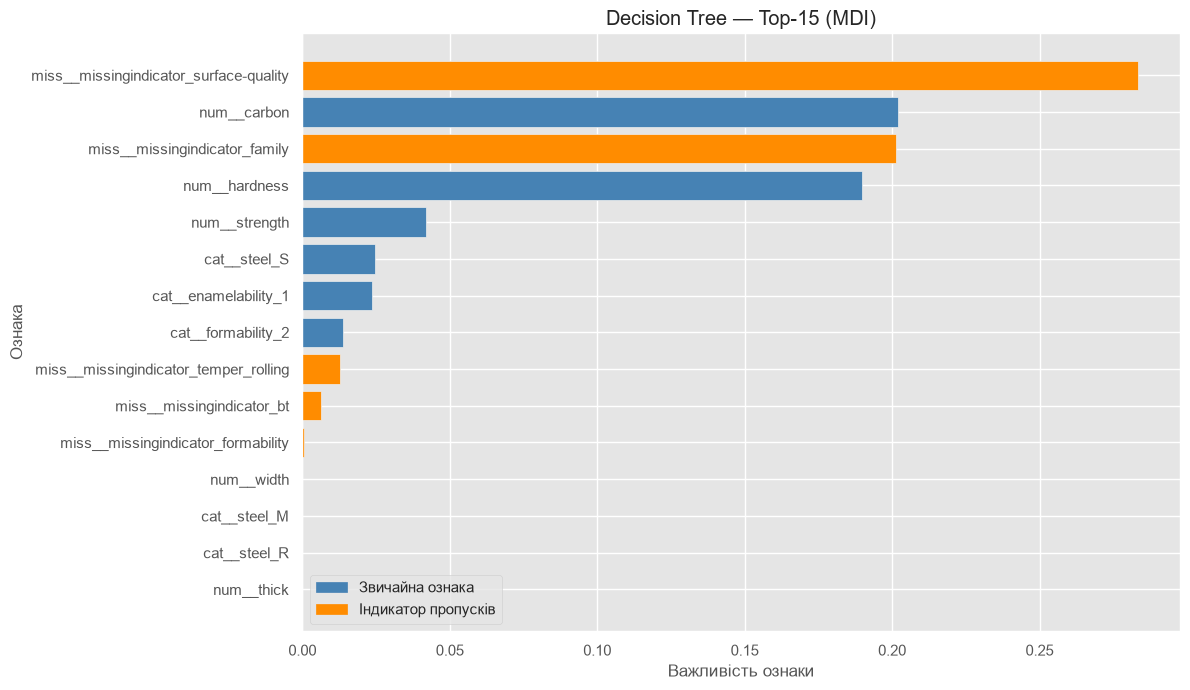

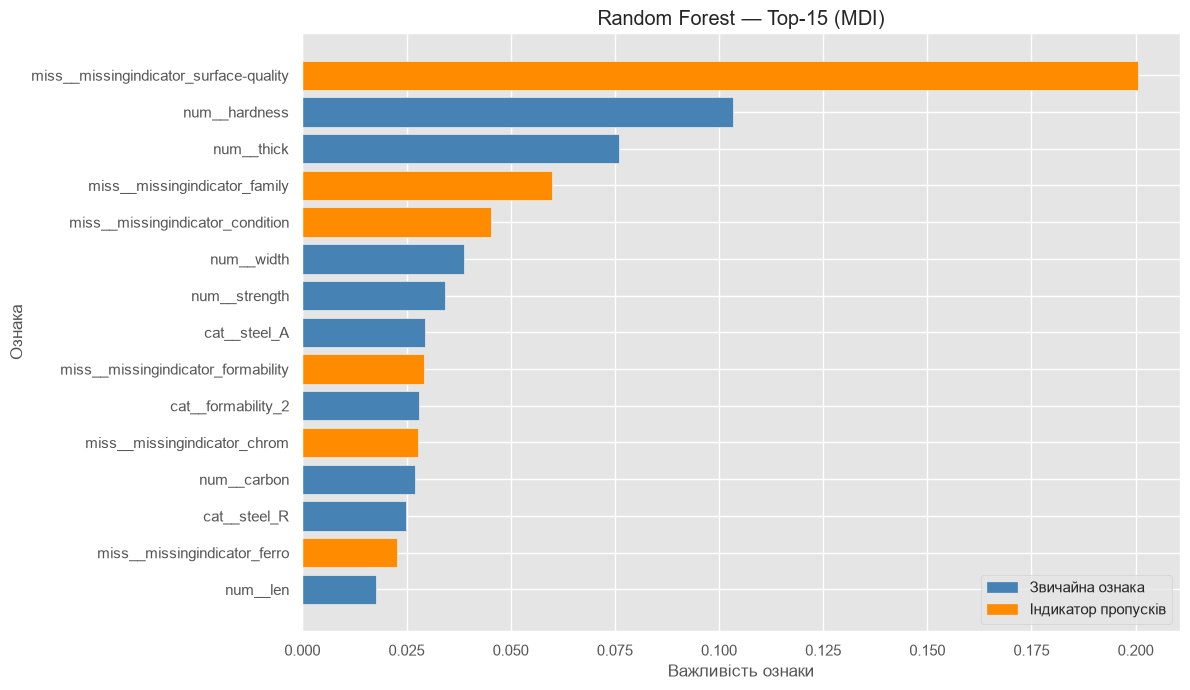

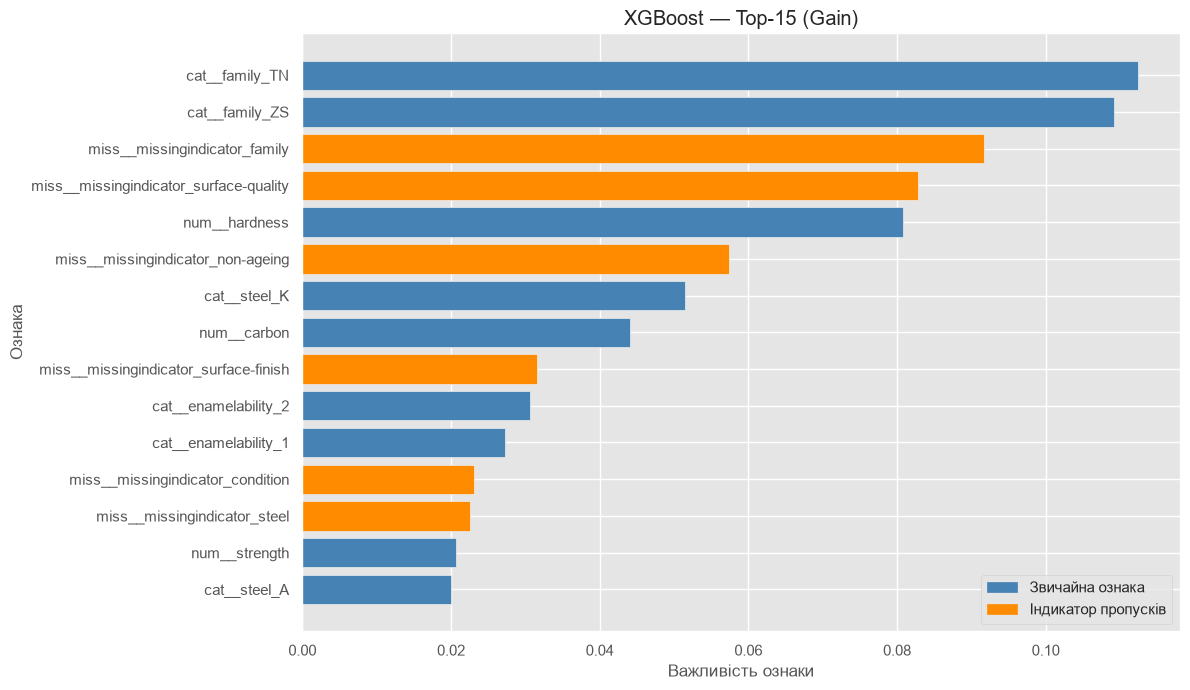

In [49]:
from matplotlib.patches import Patch

for name in MODEL_NAMES:

    top_features = (
        mdi_results[name]
        .head(15)
        .sort_values("Importance")
    )

    colors = np.where(
        top_features["Missing indicator"],
        "darkorange",
        "steelblue"
    )

    plt.figure(figsize=(12, 7))

    plt.barh(
        top_features["Feature"],
        top_features["Importance"],
        color=colors
    )

    importance_type = (
        "Gain" if name == "XGB" else "MDI"
    )

    plt.title(
        f"{MODEL_LABELS[name]} — Top-15 ({importance_type})"
    )

    plt.xlabel("Важливість ознаки")
    plt.ylabel("Ознака")

    plt.legend(handles=[
        Patch(
            color="steelblue",
            label="Звичайна ознака"
        ),
        Patch(
            color="darkorange",
            label="Індикатор пропусків"
        )
    ])

    plt.tight_layout()
    plt.show()

### 7.3. Аналіз внеску індикаторів пропусків

Для кожної моделі визначимо кількість індикаторів
пропусків серед 15 найважливіших ознак.

Також розрахуємо сумарну важливість усіх
індикаторів пропусків відносно загальної
важливості перетворених ознак.

In [50]:
indicator_importance_results = []

for name in MODEL_NAMES:

    importance_df = mdi_results[name]

    top15 = importance_df.head(15)

    indicators = importance_df[
        importance_df["Missing indicator"]
    ]

    total_importance = importance_df["Importance"].sum()

    indicator_importance = indicators["Importance"].sum()

    indicator_importance_results.append({
        "Model": MODEL_LABELS[name],

        "Total indicators": len(indicators),

        "Indicators in Top-15": (
            top15["Missing indicator"].sum()
        ),

        "Non-zero indicators": (
            indicators["Importance"] > 0
        ).sum(),

        "Total indicator importance": (
            indicator_importance
        ),

        "Indicator importance (%)": (
            indicator_importance /
            total_importance * 100
        )
    })

indicator_importance_df = pd.DataFrame(
    indicator_importance_results
)

display(indicator_importance_df.round(4))

,Model,Total indicators,Indicators in Top-15,Non-zero indicators,Total indicator importance,Indicator importance (%)
0,Decision Tree,23,5,5,0.5045,50.4483
1,Random Forest,23,6,23,0.4828,48.2771
2,XGBoost,23,6,15,0.3639,36.3852


**Висновок.** Аналіз MDI та Gain підтвердив значну
роль індикаторів пропущених значень у класифікації.

Для Decision Tree та Random Forest найважливішою
перетвореною ознакою став індикатор пропусків
surface-quality.

Для XGBoost найбільшу важливість отримали
категоріальні ознаки family_TN та family_ZS.

Сумарна частка важливості індикаторів пропусків
становить 50.45% для Decision Tree, 48.28% для
Random Forest та 36.39% для XGBoost.

Серед 15 найважливіших ознак Decision Tree
містить 5 індикаторів пропусків, а Random Forest
та XGBoost — по 6.

Random Forest використовує всі 23 індикатори
пропусків із ненульовою важливістю, що свідчить
про використання ширшого набору ознак ансамблем.

Отримані результати узгоджуються з попереднім
аналізом залежності пропусків від цільового класу
та покращенням метрик у варіанті B.

### 7.4. Permutation Importance

Permutation Importance визначає важливість ознаки
шляхом випадкового перемішування її значень
та вимірювання зниження якості класифікації.

Дослідження проведемо на незалежній тестовій
вибірці, використовуючи повні навчені пайплайни.

Для кожної ознаки виконаємо 10 повторень
перемішування та розрахуємо середнє зниження
Macro F1 і стандартне відхилення.

На відміну від MDI та Gain, цей метод оцінює
початкові ознаки до попередньої обробки.

Таким чином, перемішування ознаки також змінює
відповідні індикатори пропусків та результати
One-Hot Encoding.

In [51]:
N_PERMUTATIONS = 10

permutation_results = {}

for name in MODEL_NAMES:

    print(f"\nPermutation Importance: {MODEL_LABELS[name]}")

    start = time.perf_counter()

    result = permutation_importance(
        final_models[name],
        X_test,
        y_test,
        scoring="f1_macro",
        n_repeats=N_PERMUTATIONS,
        random_state=SEED,
        n_jobs=1
    )

    elapsed = time.perf_counter() - start

    importance_df = pd.DataFrame({
        "Feature": X_test.columns,
        "Importance mean": result.importances_mean,
        "Importance std": result.importances_std
    }).sort_values(
        "Importance mean",
        ascending=False
    ).reset_index(drop=True)

    permutation_results[name] = importance_df

    display(importance_df.head(15).round(6))

    print(f"Час виконання: {elapsed:.2f} с")


Permutation Importance: Decision Tree


,Feature,Importance mean,Importance std
0,surface-quality,0.457566,0.056736
1,family,0.271084,0.038595
2,formability,0.233272,0.023122
3,hardness,0.186260,0.015537
4,steel,0.138347,0.001520
5,carbon,0.074909,0.011949
6,strength,0.037836,0.004522
7,temper_rolling,0.018598,0.012604
8,enamelability,0.009734,0.002852
9,product-type,0.000000,0.000000


Час виконання: 4.82 с

Permutation Importance: Random Forest


,Feature,Importance mean,Importance std
0,surface-quality,0.231317,0.046841
1,hardness,0.194592,0.018329
2,steel,0.179063,0.013086
3,shape,0.067028,0.067028
4,formability,0.030819,0.036867
5,strength,0.024962,0.002749
6,family,0.015535,0.013626
7,condition,0.015381,0.009518
8,enamelability,0.004489,0.002244
9,width,0.001406,0.004217


Час виконання: 21.30 с

Permutation Importance: XGBoost


,Feature,Importance mean,Importance std
0,surface-quality,0.286364,0.039231
1,hardness,0.200244,0.015591
2,strength,0.170146,0.004482
3,family,0.158367,0.053523
4,steel,0.141106,0.003857
5,width,0.120650,0.040217
6,formability,0.096585,0.063230
7,condition,0.086344,0.068630
8,len,0.071638,0.068457
9,temper_rolling,0.040217,0.061432


Час виконання: 7.08 с


### 7.5. Візуалізація Permutation Importance

Для кожної моделі побудуємо горизонтальну діаграму
15 найважливіших початкових ознак.

Стандартні відхилення відображатимуть варіативність
результатів між повтореннями перемішування.

Нульова важливість означає, що перемішування
ознаки не вплинуло на середнє значення метрики.

Від'ємна важливість означає, що після перемішування
середнє значення метрики збільшилося.

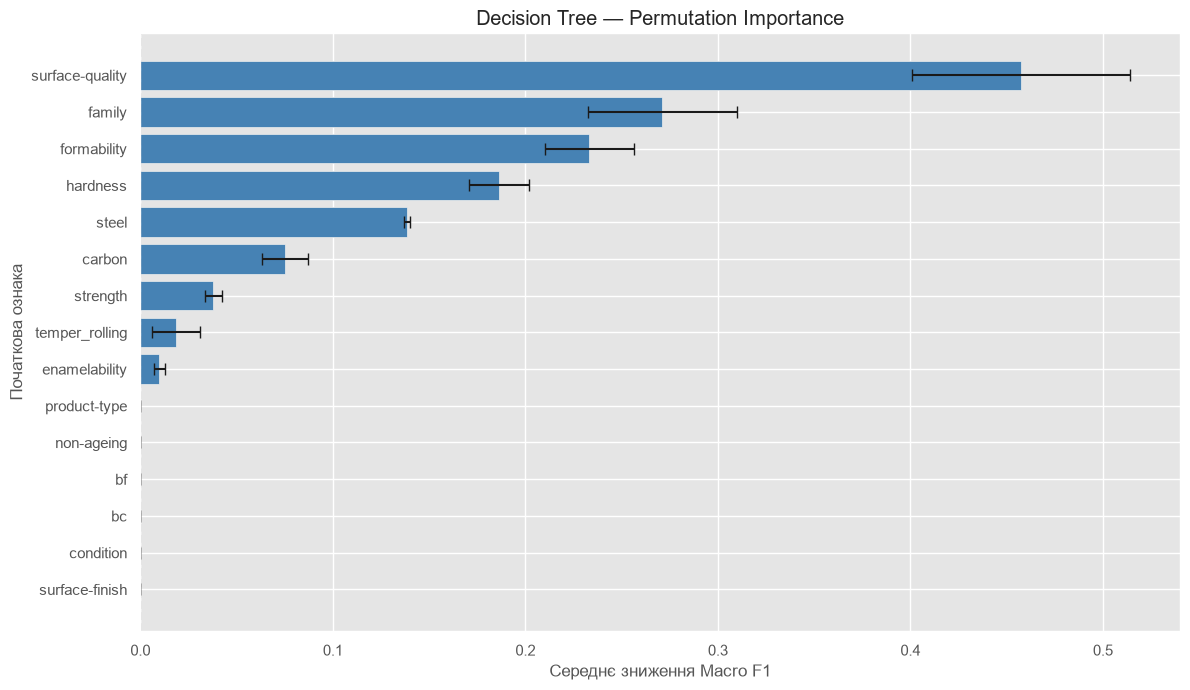

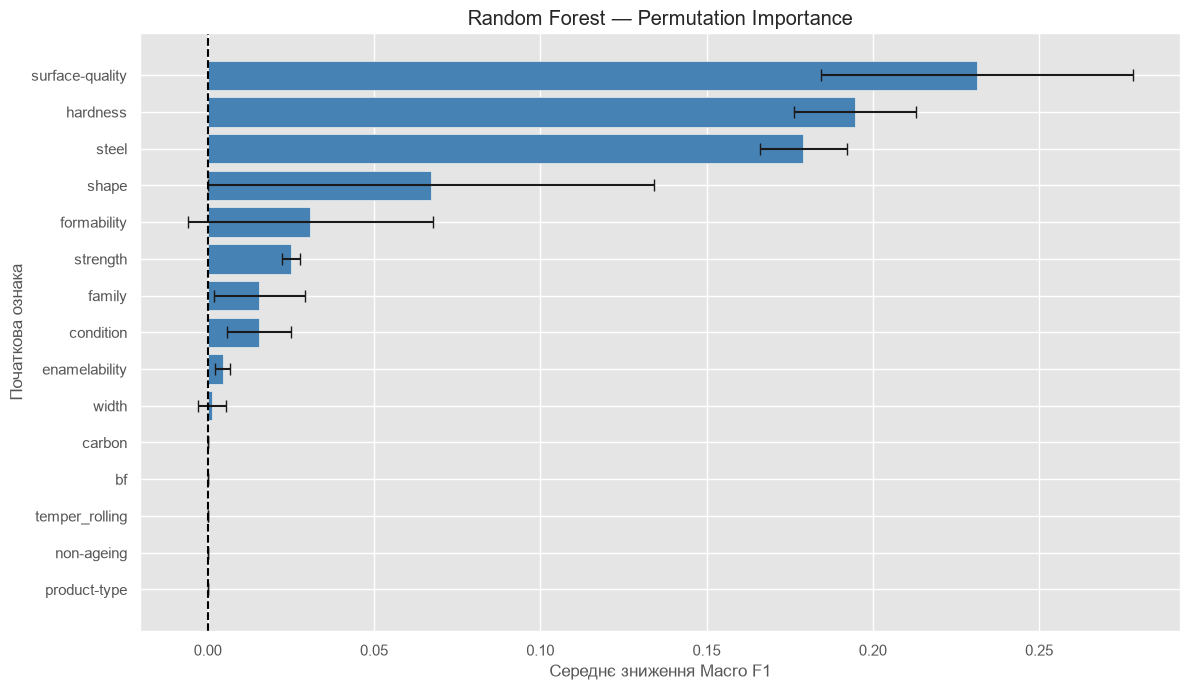

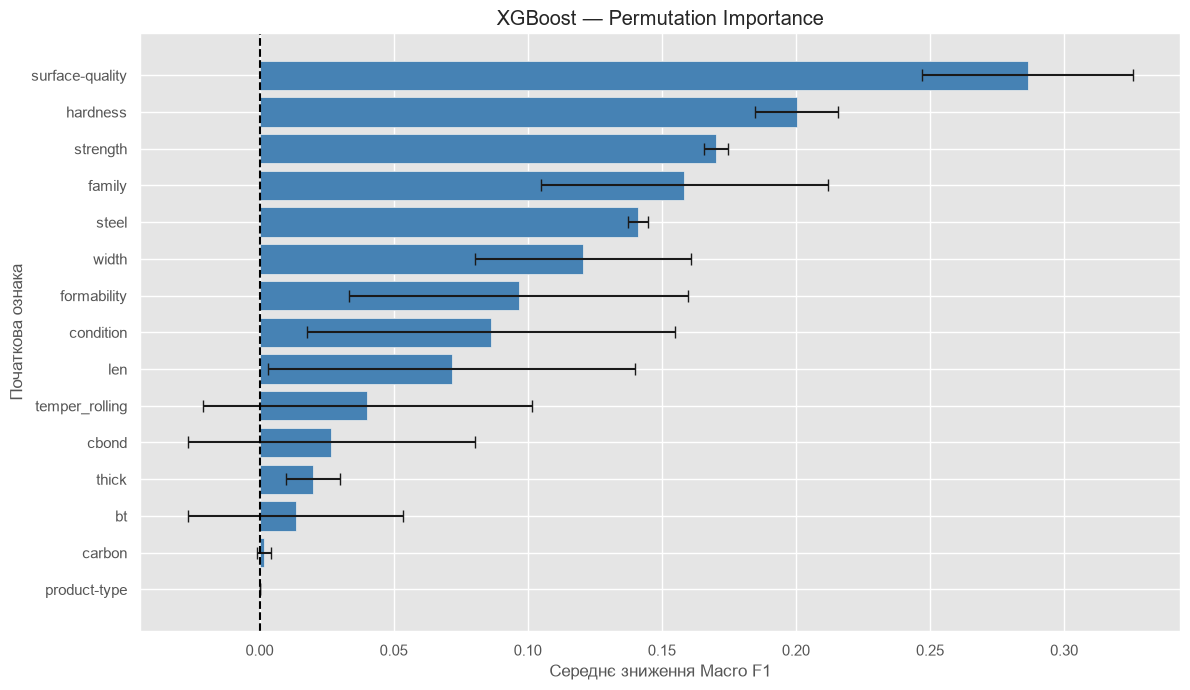

In [52]:
for name in MODEL_NAMES:

    top_features = (
        permutation_results[name]
        .head(15)
        .sort_values("Importance mean")
    )

    plt.figure(figsize=(12, 7))

    plt.barh(
        top_features["Feature"],
        top_features["Importance mean"],
        xerr=top_features["Importance std"],
        color="steelblue",
        capsize=4
    )

    plt.axvline(
        0,
        color="black",
        linestyle="--"
    )

    plt.title(
        f"{MODEL_LABELS[name]} — Permutation Importance"
    )

    plt.xlabel("Середнє зниження Macro F1")
    plt.ylabel("Початкова ознака")

    plt.tight_layout()
    plt.show()

### 7.6. Порівняння важливості ознак між моделями

Порівняємо множини 15 найважливіших ознак,
отриманих методом Permutation Importance.

Для кількісної оцінки подібності використаємо
коефіцієнт Жаккара, який визначається як
відношення розміру перетину множин до розміру
їхнього об'єднання.

In [53]:
from itertools import combinations

top_features_by_model = {
    name: set(
        permutation_results[name]
        .head(15)["Feature"]
    )
    for name in MODEL_NAMES
}

feature_comparison = []

for name_a, name_b in combinations(MODEL_NAMES, 2):

    features_a = top_features_by_model[name_a]
    features_b = top_features_by_model[name_b]

    common = features_a & features_b
    union = features_a | features_b

    feature_comparison.append({
        "Comparison": f"{name_a} - {name_b}",
        "Common features": len(common),
        "Jaccard similarity": len(common) / len(union),
        "Features": ", ".join(sorted(common))
    })

display(
    pd.DataFrame(feature_comparison).round(4)
)

common_all = set.intersection(
    *top_features_by_model.values()
)

print("Спільні ознаки для всіх трьох моделей:")

print(sorted(common_all))

,Comparison,Common features,Jaccard similarity,Features
0,DT - RF,13,0.7647,"bf, carbon, condition, enamelability, family, ..."
1,DT - XGB,10,0.5000,"carbon, condition, family, formability, hardne..."
2,RF - XGB,11,0.5789,"carbon, condition, family, formability, hardne..."


Спільні ознаки для всіх трьох моделей:
['carbon', 'condition', 'family', 'formability', 'hardness', 'product-type', 'steel', 'strength', 'surface-quality', 'temper_rolling']


### 7.7. Порівняння методів оцінювання важливості

Для порівняння MDI/Gain та Permutation Importance
згрупуємо перетворені ознаки за відповідними
початковими ознаками.

Важливість категорій One-Hot Encoding та індикаторів
пропусків додаватиметься до важливості відповідної
початкової ознаки.

Після цього порівняємо рейтинги важливості
за допомогою рангової кореляції Спірмена.

In [54]:
def get_original_feature(transformed_name):

    if transformed_name.startswith("miss__missingindicator_"):
        return transformed_name.removeprefix(
            "miss__missingindicator_"
        )

    if transformed_name.startswith("num__"):
        return transformed_name.removeprefix("num__")

    if transformed_name.startswith("cat__"):

        raw_name = transformed_name.removeprefix("cat__")

        for col in sorted(X.columns, key=len, reverse=True):

            if raw_name.startswith(f"{col}_"):
                return col

    raise ValueError(
        f"Невідома ознака: {transformed_name}"
    )


importance_comparison_results = []

for name in MODEL_NAMES:

    grouped = mdi_results[name].copy()

    grouped["Original feature"] = (
        grouped["Feature"].map(get_original_feature)
    )

    grouped = (
        grouped.groupby("Original feature")["Importance"]
        .sum()
        .reindex(X.columns, fill_value=0)
        .rename("MDI / Gain")
    )

    permutation = (
        permutation_results[name]
        .set_index("Feature")["Importance mean"]
        .rename("Permutation")
    )

    comparison = pd.concat(
        [grouped, permutation],
        axis=1
    )

    rho, p_value = stats.spearmanr(
        comparison["MDI / Gain"],
        comparison["Permutation"]
    )

    mdi_top = set(
        comparison["MDI / Gain"].nlargest(15).index
    )

    permutation_top = set(
        comparison["Permutation"].nlargest(15).index
    )

    importance_comparison_results.append({
        "Model": MODEL_LABELS[name],
        "Spearman correlation": rho,
        "p-value": p_value,
        "Common Top-15": len(mdi_top & permutation_top)
    })

    print(f"\nМодель: {MODEL_LABELS[name]}")

    display(
        comparison.sort_values(
            "Permutation",
            ascending=False
        ).head(15).round(6)
    )

display(
    pd.DataFrame(
        importance_comparison_results
    ).round(6)
)


Модель: Decision Tree


,MDI / Gain,Permutation
surface-quality,0.283462,0.457566
family,0.201177,0.271084
formability,0.014405,0.233272
hardness,0.189784,0.186260
steel,0.024470,0.138347
carbon,0.201889,0.074909
strength,0.041963,0.037836
temper_rolling,0.012784,0.018598
enamelability,0.023698,0.009734
product-type,0.000000,0.000000



Модель: Random Forest


,MDI / Gain,Permutation
surface-quality,0.218463,0.231317
hardness,0.103294,0.194592
steel,0.083510,0.179063
shape,0.021576,0.067028
formability,0.079266,0.030819
strength,0.034249,0.024962
family,0.079932,0.015535
condition,0.056245,0.015381
enamelability,0.016795,0.004489
width,0.038807,0.001406



Модель: XGBoost


,MDI / Gain,Permutation
surface-quality,0.089579,0.286364
hardness,0.080761,0.200244
strength,0.020729,0.170146
family,0.313348,0.158367
steel,0.155567,0.141106
width,0.002670,0.120650
formability,0.027637,0.096585
condition,0.041540,0.086344
len,0.003003,0.071638
temper_rolling,0.008230,0.040217


,Model,Spearman correlation,p-value,Common Top-15
0,Decision Tree,0.952426,0.000000,14
1,Random Forest,0.710506,0.000001,11
2,XGBoost,0.683573,0.000002,11


**Висновок.** За результатами Permutation Importance
найважливішою початковою ознакою для всіх трьох
моделей стала surface-quality.

Її перемішування спричинило середнє зниження
Macro F1 на 0.4576 для Decision Tree, 0.2313
для Random Forest та 0.2864 для XGBoost.

Також значну роль відіграють hardness, family,
steel, formability та strength.

Найбільшу узгодженість між рейтингами MDI
та Permutation Importance отримано для Decision Tree:
коефіцієнт кореляції Спірмена становить 0.9524.

Для Random Forest цей коефіцієнт становить 0.7105,
а для XGBoost — 0.6836.

Відмінності між рейтингами пояснюються різними
принципами оцінювання важливості, взаємозалежністю
ознак та особливостями побудови моделей.

MDI може надавати перевагу ознакам із великою
кількістю можливих розбиттів, тоді як Permutation
Importance може недооцінювати важливість
взаємозамінних корельованих ознак.

Наявність ознак із нульовою важливістю серед
Top-15 обмежує інтерпретацію коефіцієнта Жаккара.

Загалом обидва методи підтверджують важливість
інформації про пропущені значення для класифікації.

## 8. Аналіз розбіжностей прогнозів та інтерпретація моделей за допомогою SHAP

### 8.1. Виявлення розбіжностей прогнозів

Порівняємо прогнози Decision Tree, Random Forest
та XGBoost для об'єктів тестової вибірки.

Розбіжністю вважатимемо ситуацію, коли хоча б
одна модель прогнозує клас, відмінний від
прогнозів інших моделей.

Визначимо кількість таких об'єктів та сформуємо
таблицю фактичних і прогнозованих класів.

In [55]:
predictions_df = pd.DataFrame({
    "Object index": X_test.index,
    "True class": label_encoder.inverse_transform(y_test)
})

for name in MODEL_NAMES:

    predictions_df[name] = label_encoder.inverse_transform(
        test_predictions[name]
    )

predictions_df["Disagreement"] = (
    predictions_df[MODEL_NAMES].nunique(axis=1) > 1
)

disagreement_df = predictions_df[
    predictions_df["Disagreement"]
].copy()

disagreement_df["Source"] = "Test"

print("Кількість тестових об'єктів:", len(X_test))
print("Кількість розбіжностей:", len(disagreement_df))

print(
    "Частка розбіжностей:",
    f"{len(disagreement_df) / len(X_test) * 100:.2f}%"
)

display(disagreement_df)

Кількість тестових об'єктів: 180
Кількість розбіжностей: 4
Частка розбіжностей: 2.22%


,Object index,True class,DT,RF,XGB,Disagreement,Source
10,308,3,2,3,3,True,Test
25,453,U,3,U,U,True,Test
34,746,3,3,3,2,True,Test
116,101,3,2,3,3,True,Test


### 8.2. Формування таблиці розбіжностей

Для аналізу необхідно отримати щонайменше три
об'єкти, для яких прогнози моделей відрізняються.

Якщо кількість таких об'єктів у тестовій вибірці
недостатня, використаємо Out-of-Fold прогнози
зовнішніх блоків вкладеної крос-валідації.

Кожен OOF-прогноз формується моделлю, яка не
використовувала відповідний об'єкт для навчання
або оптимізації гіперпараметрів.

In [56]:
oof_models = {}

if len(disagreement_df) < 3:

    print("Доповнення результатів OOF-прогнозами")

    oof_predictions = {
        name: np.full(len(X_train), -1, dtype=int)
        for name in MODEL_NAMES
    }

    for fold, (tr_idx, va_idx) in enumerate(outer_splits):

        for name in MODEL_NAMES:

            pipeline = build_pipeline(
                name,
                with_indicators=True,
                params=nested_studies[name][fold].best_params
            )

            pipeline.fit(
                X_train.iloc[tr_idx],
                y_train[tr_idx]
            )

            oof_predictions[name][va_idx] = pipeline.predict(
                X_train.iloc[va_idx]
            )

            oof_models[(fold, name)] = pipeline

    oof_df = pd.DataFrame({
        "Object index": X_train.index,
        "True class": label_encoder.inverse_transform(y_train)
    })

    for name in MODEL_NAMES:

        oof_df[name] = label_encoder.inverse_transform(
            oof_predictions[name]
        )

    oof_df["Disagreement"] = (
        oof_df[MODEL_NAMES].nunique(axis=1) > 1
    )

    oof_df = oof_df[oof_df["Disagreement"]].copy()
    oof_df["Source"] = "OOF"

    disagreement_df = pd.concat(
        [disagreement_df, oof_df],
        ignore_index=True
    )

print("Таблиця 7. Об'єкти з розбіжностями прогнозів")

display(
    disagreement_df[[
        "Object index",
        "Source",
        "True class",
        "DT",
        "RF",
        "XGB"
    ]]
)

print("Загальна кількість розбіжностей:", len(disagreement_df))

Таблиця 7. Об'єкти з розбіжностями прогнозів


,Object index,Source,True class,DT,RF,XGB
10,308,Test,3,2,3,3
25,453,Test,U,3,U,U
34,746,Test,3,3,3,2
116,101,Test,3,2,3,3


Загальна кількість розбіжностей: 4


### 8.3. Вибір об'єкта для детального аналізу

Виберемо один об'єкт, для якого прогнози моделей
відрізняються.

За можливості надамо перевагу об'єкту рідкісного
класу 1, оскільки попередній аналіз показав,
що цей клас є найскладнішим для класифікації.

Дослідимо початкові значення всіх його ознак,
наявність пропусків та прогнози кожної моделі.

In [57]:
rare_disagreements = disagreement_df[
    disagreement_df["True class"].astype(str) == "1"
]

if not rare_disagreements.empty:
    selected = rare_disagreements.iloc[0]
else:
    selected = disagreement_df.iloc[0]

selected_index = selected["Object index"]
selected_source = selected["Source"]

if selected_source == "Test":

    selected_object = X_test.loc[[selected_index]]
    analysis_models = final_models

else:

    selected_object = X_train.loc[[selected_index]]

    selected_position = X_train.index.get_loc(selected_index)

    selected_fold = next(
        fold
        for fold, (_, va_idx) in enumerate(outer_splits)
        if selected_position in va_idx
    )

    analysis_models = {
        name: oof_models[(selected_fold, name)]
        for name in MODEL_NAMES
    }

print("Індекс об'єкта:", selected_index)
print("Джерело:", selected_source)
print("Фактичний клас:", selected["True class"])

object_features = pd.DataFrame({
    "Feature": selected_object.columns,
    "Original value": selected_object.iloc[0].values,
    "Missing": selected_object.iloc[0].isna().values
})

display(object_features)

print(
    "Кількість пропущених значень:",
    selected_object.isna().sum().sum()
)

Індекс об'єкта: 308
Джерело: Test
Фактичний клас: 3


,Feature,Original value,Missing
0,family,NaN,True
1,product-type,C,False
2,steel,R,False
3,carbon,0.0,False
4,hardness,0.0,False
5,temper_rolling,NaN,True
6,condition,NaN,True
7,formability,NaN,True
8,strength,500.0,False
9,non-ageing,NaN,True


Кількість пропущених значень: 28


### 8.4. Аналіз імпутації вибраного об'єкта

Для вибраного об'єкта визначимо, якими значеннями
було замінено пропуски під час попередньої обробки.

Числові пропуски замінюються медіаною, а
категоріальні — найчастішим значенням відповідної
ознаки у тренувальній вибірці.

Також перевіримо значення бінарних індикаторів
пропусків.

In [58]:
imputation_results = []

for name in MODEL_NAMES:

    pipeline = analysis_models[name]

    dropped = pipeline.named_steps["drop"].transform(
        selected_object
    )

    prep = pipeline.named_steps["prep"]

    for transformer_name, transformer, columns in prep.transformers_:

        if transformer_name not in ["num", "cat"]:
            continue

        if transformer_name == "num":
            imputer = transformer
        else:
            imputer = transformer.named_steps["impute"]

        for feature, fill_value in zip(
            columns,
            imputer.statistics_
        ):

            if pd.isna(dropped.iloc[0][feature]):

                imputation_results.append({
                    "Model": name,
                    "Feature": feature,
                    "Original value": "Missing",
                    "Imputed value": fill_value,
                    "Missing indicator": 1
                })

    for feature in pipeline.named_steps["drop"].drop_columns_:

        if pd.isna(selected_object.iloc[0][feature]):

            imputation_results.append({
                "Model": name,
                "Feature": feature,
                "Original value": "Missing",
                "Imputed value": "Removed",
                "Missing indicator": "—"
            })

imputation_df = pd.DataFrame(imputation_results)

display(imputation_df)

,Model,Feature,Original value,Imputed value,Missing indicator
0,DT,family,Missing,TN,1
1,DT,temper_rolling,Missing,T,1
2,DT,condition,Missing,S,1
3,DT,formability,Missing,2,1
4,DT,non-ageing,Missing,N,1
...,...,...,...,...,...
79,XGB,marvi,Missing,Removed,—
80,XGB,corr,Missing,Removed,—
81,XGB,jurofm,Missing,Removed,—
82,XGB,s,Missing,Removed,—


### 8.5. Порівняння ймовірностей прогнозованих класів

Для кожної моделі визначимо оцінені ймовірності
належності вибраного об'єкта до кожного класу.

Це дозволить дослідити впевненість моделей
у власних прогнозах та визначити, між якими
класами виникає найбільша неоднозначність.

Decision Tree: клас 2, confidence = 0.8889
Random Forest: клас 3, confidence = 0.6133
XGBoost: клас 3, confidence = 0.6347


,DT,RF,XGB
Class,,,
1,0.0000,0.2133,0.1095
2,0.8889,0.1667,0.2233
3,0.1111,0.6133,0.6347
5,0.0000,0.0000,0.0172
U,0.0000,0.0067,0.0153


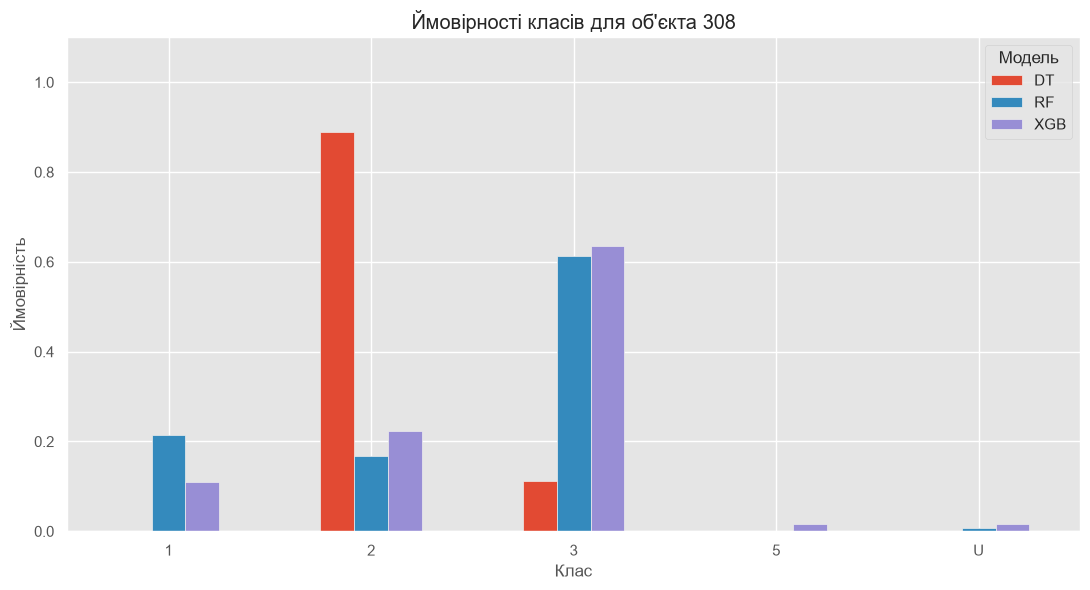

In [59]:
object_probabilities = {}
object_predictions = {}

for name in MODEL_NAMES:

    pipeline = analysis_models[name]

    probabilities = pipeline.predict_proba(
        selected_object
    )[0]

    prediction = int(
        pipeline.predict(selected_object)[0]
    )

    object_probabilities[name] = probabilities
    object_predictions[name] = prediction

    print(
        f"{MODEL_LABELS[name]}: "
        f"клас {class_names[prediction]}, "
        f"confidence = {probabilities[prediction]:.4f}"
    )

probability_df = pd.DataFrame(
    object_probabilities,
    index=class_names
)

probability_df.index.name = "Class"

display(probability_df.round(4))

probability_df.plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

plt.title(
    f"Ймовірності класів для об'єкта {selected_index}"
)

plt.xlabel("Клас")
plt.ylabel("Ймовірність")
plt.ylim(0, 1.1)
plt.legend(title="Модель")
plt.tight_layout()
plt.show()

### 8.6. Інтерпретація прогнозів за допомогою SHAP

Для локальної інтерпретації прогнозів використаємо
метод SHAP (SHapley Additive exPlanations).

SHAP визначає внесок кожної ознаки у відхилення
виходу моделі від базового значення.

Оскільки всі досліджувані моделі побудовані
на основі дерев, використаємо shap.TreeExplainer.

Для кожної моделі визначимо п'ять ознак із
найбільшими абсолютними значеннями SHAP
для прогнозованого нею класу.

Додатні значення SHAP збільшують вихід моделі
для відповідного класу, а від'ємні — зменшують.

Для Decision Tree та Random Forest пояснюється
ймовірність класу, а для XGBoost — raw margin
до застосування функції softmax.

Тому абсолютні значення SHAP різних алгоритмів
не слід безпосередньо порівнювати між собою.

In [60]:
shap_results = {}
shap_summary = []

for name in MODEL_NAMES:

    pipeline = analysis_models[name]

    X_object_transformed = pipeline[:-1].transform(
        selected_object
    )

    feature_names = pipeline[:-1].get_feature_names_out()

    model = pipeline.named_steps["clf"]

    predicted_class = object_predictions[name]

    explainer = shap.TreeExplainer(model)

    explanation = explainer(
        X_object_transformed
    )

    values = np.asarray(explanation.values)

    # Для багатокласової класифікації:
    # (samples, features, classes)

    if values.ndim != 3:
        raise ValueError(
            f"Unexpected SHAP shape: {values.shape}"
        )

    class_values = values[0, :, predicted_class]

    shap_df = pd.DataFrame({
        "Feature": feature_names,
        "Value": X_object_transformed[0],
        "SHAP value": class_values,
        "Absolute SHAP": np.abs(class_values)
    }).sort_values(
        "Absolute SHAP",
        ascending=False
    ).reset_index(drop=True)

    shap_df["Missing indicator"] = (
        shap_df["Feature"].str.startswith("miss__")
    )

    shap_results[name] = shap_df

    top5 = shap_df.head(5)

    shap_summary.append({
        "Model": MODEL_LABELS[name],
        "Predicted class": class_names[predicted_class],
        "Confidence": object_probabilities[name][predicted_class],
        "Most important feature": top5.iloc[0]["Feature"],
        "Indicators in Top-5": top5["Missing indicator"].sum()
    })

    print(f"\nМодель: {MODEL_LABELS[name]}")
    print("SHAP shape:", values.shape)
    print("Прогнозований клас:", class_names[predicted_class])

    display(top5.round(6))


Модель: Decision Tree
SHAP shape: (1, 77, 5)
Прогнозований клас: 2


,Feature,Value,SHAP value,Absolute SHAP,Missing indicator
0,miss__missingindicator_surface-quality,1.0,0.434252,0.434252,True
1,num__carbon,0.0,0.199701,0.199701,False
2,miss__missingindicator_family,1.0,0.131092,0.131092,True
3,miss__missingindicator_formability,1.0,-0.043879,0.043879,True
4,cat__enamelability_1,0.0,0.020846,0.020846,False



Модель: Random Forest
SHAP shape: (1, 77, 5)
Прогнозований клас: 3


,Feature,Value,SHAP value,Absolute SHAP,Missing indicator
0,miss__missingindicator_surface-quality,1.0,-0.189382,0.189382,True
1,miss__missingindicator_formability,1.0,0.062898,0.062898,True
2,num__thick,1.6,-0.048413,0.048413,False
3,num__carbon,0.0,-0.038187,0.038187,False
4,miss__missingindicator_condition,1.0,0.027477,0.027477,True



Модель: XGBoost
SHAP shape: (1, 77, 5)
Прогнозований клас: 3


,Feature,Value,SHAP value,Absolute SHAP,Missing indicator
0,miss__missingindicator_surface-quality,1.0,-1.357701,1.357701,True
1,num__strength,500.0,0.518460,0.518460,False
2,num__carbon,0.0,-0.334350,0.334350,False
3,num__thick,1.6,-0.304061,0.304061,False
4,num__width,609.9,-0.249502,0.249502,False


### 8.7. Візуалізація внеску ознак SHAP

Для кожної моделі побудуємо горизонтальну
стовпчикову діаграму п'яти найвпливовіших ознак
для прогнозованого класу вибраного об'єкта.

Червоним кольором позначимо додатний внесок,
а синім — від'ємний.

Це дозволить порівняти локальні механізми
формування прогнозів різними моделями.

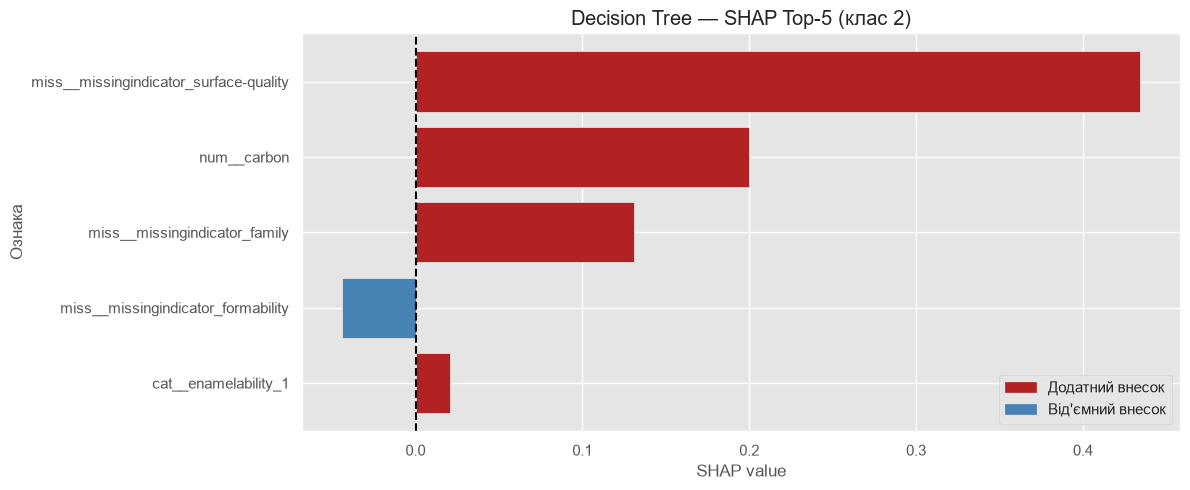

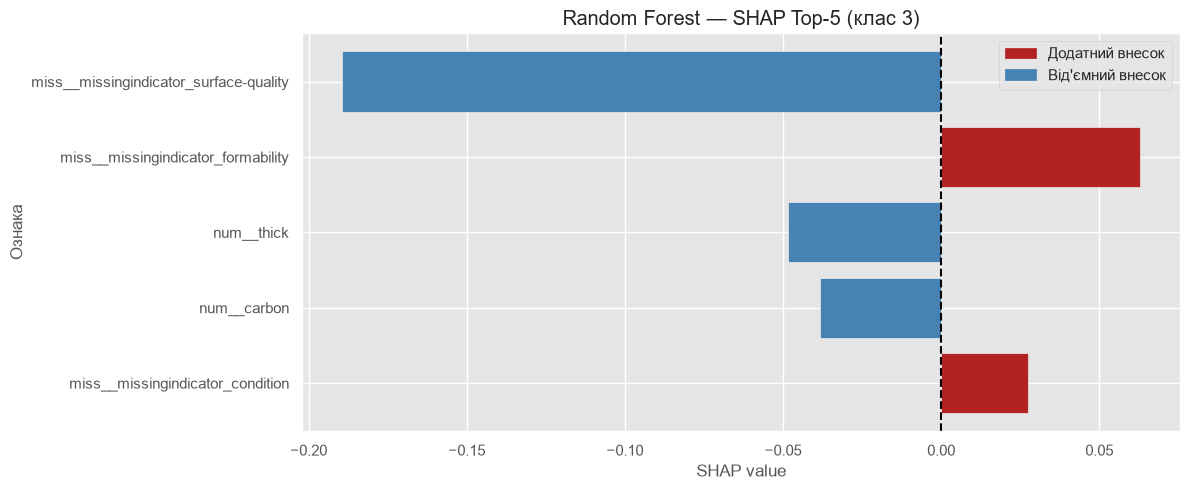

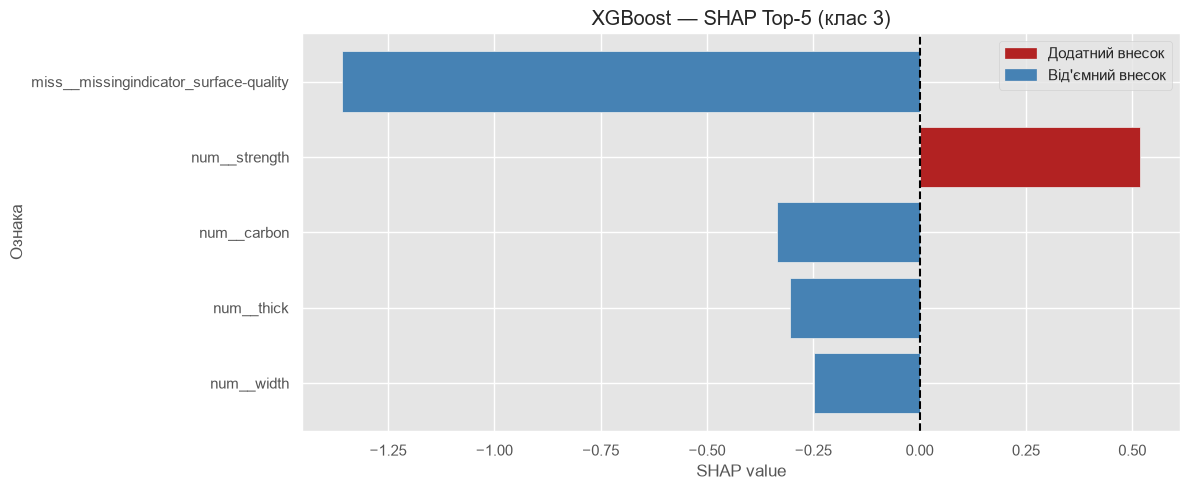

In [61]:
for name in MODEL_NAMES:

    top5 = (
        shap_results[name]
        .head(5)
        .sort_values("Absolute SHAP")
    )

    colors = np.where(
        top5["SHAP value"] > 0,
        "firebrick",
        "steelblue"
    )

    predicted_class = class_names[
        object_predictions[name]
    ]

    plt.figure(figsize=(12, 5))

    plt.barh(
        top5["Feature"],
        top5["SHAP value"],
        color=colors
    )

    plt.axvline(
        0,
        color="black",
        linestyle="--"
    )

    plt.title(
        f"{MODEL_LABELS[name]} — SHAP Top-5 "
        f"(клас {predicted_class})"
    )

    plt.xlabel("SHAP value")
    plt.ylabel("Ознака")

    plt.legend(handles=[
        Patch(
            color="firebrick",
            label="Додатний внесок"
        ),
        Patch(
            color="steelblue",
            label="Від'ємний внесок"
        )
    ])

    plt.tight_layout()
    plt.show()

### 8.8. Порівняння локальних пояснень моделей

Порівняємо прогнозовані класи, впевненість моделей,
найважливіші ознаки та кількість індикаторів
пропусків серед п'яти найвпливовіших ознак.

Проаналізуємо, чи використовують моделі однакові
ознаки для формування прогнозів та як особливості
дерев рішень, бегінгу і градієнтного бустингу
впливають на виникнення розбіжностей.

In [62]:
shap_summary_df = pd.DataFrame(shap_summary)

print("Фактичний клас:", selected["True class"])
print("Індекс об'єкта:", selected_index)

display(shap_summary_df.round(4))

shap_top_features = {
    name: set(
        shap_results[name].head(5)["Feature"]
    )
    for name in MODEL_NAMES
}

common_shap_features = set.intersection(
    *shap_top_features.values()
)

print("Спільні ознаки SHAP Top-5:")

print(sorted(common_shap_features))

for name in MODEL_NAMES:

    indicators = shap_results[name].head(5)

    indicators = indicators[
        indicators["Missing indicator"]
    ]

    print(f"\nІндикатори пропусків: {MODEL_LABELS[name]}")

    display(
        indicators[[
            "Feature",
            "Value",
            "SHAP value"
        ]].round(6)
    )

Фактичний клас: 3
Індекс об'єкта: 308


,Model,Predicted class,Confidence,Most important feature,Indicators in Top-5
0,Decision Tree,2,0.8889,miss__missingindicator_surface-quality,3
1,Random Forest,3,0.6133,miss__missingindicator_surface-quality,3
2,XGBoost,3,0.6347,miss__missingindicator_surface-quality,1


Спільні ознаки SHAP Top-5:
['miss__missingindicator_surface-quality', 'num__carbon']

Індикатори пропусків: Decision Tree


,Feature,Value,SHAP value
0,miss__missingindicator_surface-quality,1.0,0.434252
2,miss__missingindicator_family,1.0,0.131092
3,miss__missingindicator_formability,1.0,-0.043879



Індикатори пропусків: Random Forest


,Feature,Value,SHAP value
0,miss__missingindicator_surface-quality,1.0,-0.189382
1,miss__missingindicator_formability,1.0,0.062898
4,miss__missingindicator_condition,1.0,0.027477



Індикатори пропусків: XGBoost


,Feature,Value,SHAP value
0,miss__missingindicator_surface-quality,1.0,-1.357701


**Висновок.** У результаті порівняння прогнозів
трьох фінальних моделей виявлено 4 об'єкти
з розбіжностями, що становить 2.22% тестової вибірки.

Для детального аналізу вибрано об'єкт з індексом 308,
який належить до класу 3 та містить 28 пропущених
значень із 38 початкових ознак.

Decision Tree помилково класифікувало цей об'єкт
як клас 2 з оціненою ймовірністю 0.8889.

Random Forest та XGBoost правильно визначили
клас 3 з ймовірностями 0.6133 та 0.6347 відповідно.

За результатами SHAP найбільший абсолютний внесок
у прогноз усіх трьох моделей має індикатор
пропусків surface-quality.

Для Decision Tree цей індикатор збільшує
оцінену ймовірність класу 2, тоді як для
Random Forest та XGBoost зменшує вихід моделі
для класу 3.

Попри цей негативний внесок, ансамблеві моделі
правильно класифікували об'єкт завдяки сукупному
впливу інших ознак та базового значення.

Серед п'яти найвпливовіших ознак Decision Tree
та Random Forest містять по три індикатори
пропусків, а XGBoost — один.

Отримані результати демонструють відмінності
локальних механізмів формування прогнозів
одиночного дерева, бегінгу та градієнтного бустингу.

Метод SHAP дозволив пояснити внески окремих
ознак та підтвердити важливість інформації
про пропущені значення.

## 9. Висновок

У ході лабораторної роботи досліджено методи
Decision Tree, Random Forest та XGBoost у задачі
багатокласової класифікації набору даних Annealing,
який містить 898 спостережень, 38 ознак, 5 класів
та 64.98% пропущених значень.

Статистичний аналіз показав наявність залежності
між пропусками окремих ознак та цільовим класом,
що обґрунтувало використання індикаторів пропусків.

Додавання індикаторів покращило Macro F1 усіх
базових моделей, причому найбільший відносний
приріст отримано для Decision Tree — 7.01%.

Скоригований t-критерій Nadeau–Bengio підтвердив
статистичну значущість цього покращення для
Random Forest (p = 0.000222) та XGBoost
(p = 0.027645), однак не підтвердив значущої
переваги Random Forest над Decision Tree.

За результатами вкладеної крос-валідації
найкращою та найстабільнішою моделлю стала
Random Forest із Macro F1 = 0.9881 ± 0.0116.

Значення Optuna best_value для всіх моделей
виявилися нижчими за оцінки вкладеної
крос-валідації, що може пояснюватися різними
схемами поділу даних та малою кількістю
спостережень рідкісного класу.

Найбільший описовий приріст Macro F1 після
оптимізації отримано для XGBoost — з 0.9713
до 0.9835, хоча різні схеми крос-валідації
не дозволяють однозначно приписати цей приріст
оптимізації гіперпараметрів.

На незалежній тестовій вибірці Random Forest
отримала найкращі результати: Accuracy = 0.9944,
Macro F1 = 0.9326 та Balanced Accuracy = 0.9000,
правильно класифікувавши 179 зі 180 об'єктів.

Найскладнішим для класифікації виявився
рідкісний клас 1, для якого Recall становить 0.5.

Методи MDI, Gain та Permutation Importance
підтвердили важливість ознаки surface-quality,
а сумарна частка важливості індикаторів пропусків
становила від 36.39% до 50.45% залежно від моделі.

Аналіз чотирьох розбіжностей прогнозів та локальна
інтерпретація об'єкта 308 за допомогою SHAP
продемонстрували відмінності механізмів прийняття
рішень одиночного дерева та ансамблевих моделей.

Для практичного використання доцільно рекомендувати
Random Forest завдяки найкращій спостережуваній
якості та стабільності, Decision Tree — за потреби
простоти й інтерпретованості, а XGBoost — як
компроміс між якістю та обчислювальними витратами.

### 10. Відповіді на контрольні питання

### 10.1. Чому Random Forest зазвичай працює краще за Decision Tree?
Окреме дерево рішень має високу дисперсію та чутливе до змін тренувальних даних.
Random Forest навчає багато дерев на випадкових bootstrap-вибірках і використовує випадкові підмножини ознак під час розбиття вузлів. 
Це зменшує кореляцію між деревами, а усереднення їхніх прогнозів знижує дисперсію та ризик перенавчання.

### 10.2. Яка різниця між бегінгом і бустингом?
Характеристика	Бегінг (RF)	Бустинг (XGB)
Навчання дерев	Незалежне	Послідовне
Основна мета	Зменшення дисперсії	Зменшення помилки ансамблю
Формування прогнозу	Усереднення	Зважена сума внесків
Паралельне навчання дерев	Можливе	Обмежене
Ризик перенавчання	Зазвичай нижчий	Залежить від регуляризації
У бустингу кожне наступне дерево намагається покращити прогноз поточного ансамблю.

### 10.3. Чому Macro F1 та Balanced Accuracy важливі при дисбалансі класів?
Accuracy враховує загальну частку правильних прогнозів, тому може бути високою навіть при поганому розпізнаванні рідкісних класів.
Macro F1 надає однакову вагу кожному класу
Balanced Accuracy обчислює середнє значення Recall для всіх класів:
Weighted F1, на відміну від Macro F1, зважує результати відповідно до кількості об'єктів кожного класу.
У нашому експерименті прогнозування лише найбільшого класу забезпечило б Accuracy 76.18% на тренувальній вибірці, незважаючи на повне ігнорування інших класів.

### 10.4. Що таке MCAR, MAR та MNAR?
Механізм	Пояснення
MCAR	Пропуски виникають повністю випадково
MAR	Пропуски залежать від інших спостережуваних даних
MNAR	Пропуски залежать від неспостережуваних значень
Індикатори пропусків дозволяють моделі використовувати сам факт відсутності значення як додаткову інформацію.
У лабораторній виявлено залежність пропусків від цільового класу для трьох досліджуваних ознак.
 Проте однозначно розрізнити MAR та MNAR лише за спостережуваними даними неможливо.

### 10.5. Що таке Data Leakage та як його уникнути?
Data Leakage — витік інформації з валідаційної або тестової вибірки у процес навчання моделі.
Наприклад, якщо обчислити медіану для заповнення пропусків на всьому наборі даних до його поділу, інформація з тестової вибірки впливатиме на навчання.
У лабораторній використано Pipeline та ColumnTransformer, завдяки яким параметри попередньої обробки визначаються лише на відповідних тренувальних блоках.

### 10.6. Чому Optuna best_value може бути оптимістично зміщеним?
Optuna багаторазово оцінює різні комбінації гіперпараметрів на тих самих валідаційних блоках і вибирає найкращу.
Через це найкращий результат може частково залежати від випадкових особливостей конкретного поділу даних.
Nested CV розділяє оптимізацію та оцінювання: внутрішній цикл підбирає гіперпараметри, а зовнішній оцінює всю процедуру на незалежному валідаційному блоці.

### 10.7. Для чого використовується скоригований t-критерій Nadeau–Bengio?
Звичайний парний t-критерій передбачає незалежність парних різниць. Однак результати повторної крос-валідації залежні через перетин тренувальних вибірок.
Скоригований критерій враховує цю залежність, збільшуючи оцінку стандартної похибки
Це зменшує ризик помилково визнати різницю між моделями статистично значущою

### 10.8. Яка різниця між MDI та Permutation Importance?
MDI оцінює важливість ознак за зменшенням неоднорідності вузлів під час побудови дерев. Метод може надавати перевагу ознакам із великою кількістю можливих розбиттів.
Permutation Importance оцінює зниження якості моделі після випадкового перемішування значень ознаки.
Якщо дві ознаки сильно корельовані, модель може використовувати одну замість іншої. Тому перемішування лише однієї з них може не спричинити значного погіршення метрики.

### 10.9. Що таке SHAP та яка різниця між локальною і глобальною інтерпретацією?
SHAP — метод пояснення прогнозів моделі, заснований на значеннях Шеплі з теорії ігор.
Він представляє вихід моделі як суму базового значення та внесків окремих ознак
Локальна інтерпретація пояснює прогноз конкретного об'єкта, а глобальна — загальну поведінку моделі на множині об'єктів, наприклад через усереднення абсолютних SHAP-значень.
У лабораторній SHAP використано для пояснення прогнозів об'єкта №308.

### 10.10. Як XGBoost обробляє пропущені значення?
XGBoost підтримує механізм sparsity-aware split finding. Під час навчання для кожного розбиття визначається напрямок, у який доцільно направляти об'єкти з пропущеними значеннями.
Цей напрямок вибирається на основі оптимізації цільової функції.
Проте в нашому експерименті пропуски попередньо заповнювалися, а їхня наявність передавалася через окремі бінарні індикатори, щоб забезпечити однакові умови порівняння всіх моделей.

### 10.11. Які переваги Optuna порівняно з Grid Search та Random Search?
Метод	Принцип
Grid Search	Перебирає задану сітку параметрів
Random Search	Випадково вибирає параметри
Optuna TPE	Використовує результати попередніх випробувань
TPE моделює розподіли перспективних та менш перспективних гіперпараметрів і використовує їх для вибору наступних комбінацій.
Optuna також підтримує pruning — дострокове припинення неперспективних випробувань. У нашій реалізації дострокове припинення не застосовувалося.